In [1]:
print("hello world")

hello world


In [2]:
# Exploratory data Analysis (EDA) - Foresight

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


In [3]:
#  Now we load the already cleaned dataset.
#  we used the processed folder rather than the raw foalder.
df = pd.read_csv(
    "../data/processed/cleaned_household_transactions.csv"
)

df

,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency,DateTime
0,2018-09-20,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR,2018-09-20 12:04:08
1,2018-09-20,Cash,Food,snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR,2018-09-20 12:03:15
2,2018-09-19,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR,2018-09-19 00:00:00
3,2018-09-17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR,2018-09-17 23:41:17
4,2018-09-16,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR,2018-09-16 17:15:08
...,...,...,...,...,...,...,...,...,...
2447,2015-01-01,Cash,Transportation,auto,share jeep - Place T base to top,20.0,Expense,INR,2015-01-01 00:00:00
2448,2015-01-01,Cash,Transportation,auto,share auto - Place H to Place T base,20.0,Expense,INR,2015-01-01 00:00:00
2449,2015-01-01,Cash,Transportation,auto,bus - brc to Place H,30.0,Expense,INR,2015-01-01 00:00:00
2450,2015-01-01,Cash,Food,Milk,tea,10.0,Expense,INR,2015-01-01 00:00:00


In [4]:
# // now we have to resotere the datetime datatype.

# Why :- When we save a DataFrame as CSV and load it again using pd.read_csv(), Pandas generally reads date columns as object (text), not as datetime.
# In Notebook 01: We converted the dates into datetime.
# When saving as CSV: The datetime information was stored as text representations.
# In Notebook 02: We load the CSV, so we need to restore the datetime datatype.

# Check the current data types after loading the CSV.
print(df[["Date", "DateTime"]].dtypes)

# Restore datetime datatypes after reading the CSV.
df["Date"] = pd.to_datetime(df["Date"])
df["DateTime"] = pd.to_datetime(df["DateTime"])


Date        object
DateTime    object
dtype: object


In [5]:
# now we first verify the loaded dataset.

# check the number of rows and columns.
print(f"Dataset shape :- {df.shape}")

# Display the first five transactions.
print("\nFirst Five Records:")
display(df.head())

# check datatypes of all coloumns.
print("\n datatypes of all coloumns :- ")
print(df.dtypes)

# checking missing values in every coloumn.
print("\nMissing values :- ")
print(df.isnull().sum())

# checking duplicate recoard.
print("\nDuplicate values :- ")
print(df.duplicated().sum())

Dataset shape :- (2452, 9)

First Five Records:


,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency,DateTime
0,2018-09-20,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR,2018-09-20 12:04:08
1,2018-09-20,Cash,Food,snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR,2018-09-20 12:03:15
2,2018-09-19,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR,2018-09-19 00:00:00
3,2018-09-17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR,2018-09-17 23:41:17
4,2018-09-16,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR,2018-09-16 17:15:08



 datatypes of all coloumns :- 
Date              datetime64[ns]
Mode                      object
Category                  object
Subcategory               object
Note                      object
Amount                   float64
Income/Expense            object
Currency                  object
DateTime          datetime64[ns]
dtype: object

Missing values :- 
Date              0
Mode              0
Category          0
Subcategory       0
Note              0
Amount            0
Income/Expense    0
Currency          0
DateTime          0
dtype: int64

Duplicate values :- 
0


In [6]:
# EDA part 1 :- financial overview 
### TRansaction type distripution. 

# count the number of transaction of each type
transaction_counts = df["Income/Expense"].value_counts()

# Display the transaction counts.
print("Transaction type distribution :- ")
print(transaction_counts)

Transaction type distribution :- 
Income/Expense
Expense         2173
Transfer-Out     154
Income           125
Name: count, dtype: int64


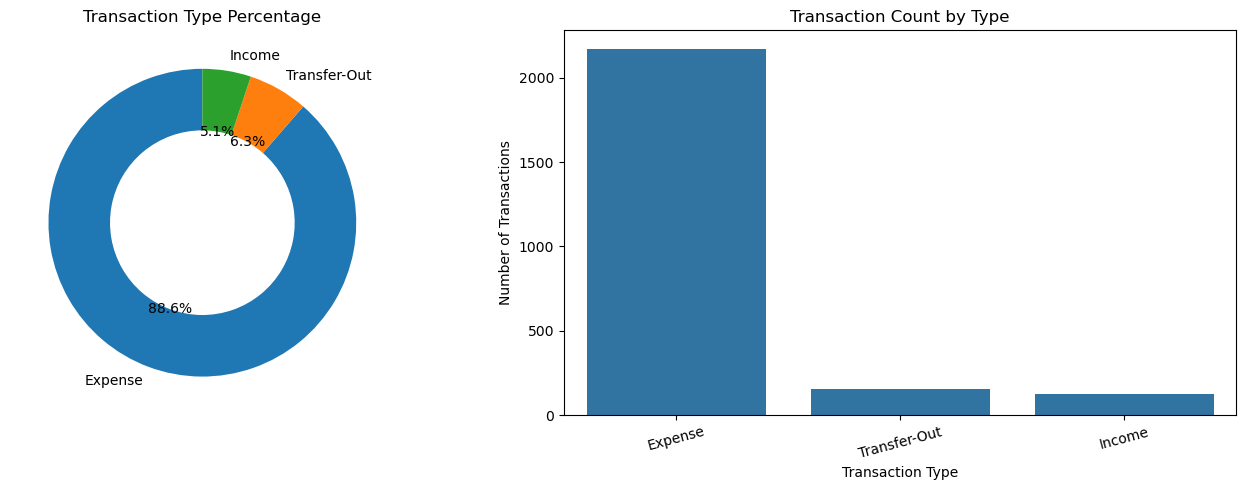

In [7]:
#  now see the transactin distribution :-

# Create a figure containing two charts side by side.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -------- Doughnut Chart --------

# Calculate transaction percentages.
transaction_percentages = (
    transaction_counts / transaction_counts.sum()
) * 100

# Draw the doughnut chart.
axes[0].pie(
    transaction_counts,
    labels=transaction_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

axes[0].set_title("Transaction Type Percentage")

# -------- Bar Chart --------

# Draw the transaction count bar chart.
sns.barplot(
    x=transaction_counts.index,
    y=transaction_counts.values,
    ax=axes[1]
)

axes[1].set_title("Transaction Count by Type")
axes[1].set_xlabel("Transaction Type")
axes[1].set_ylabel("Number of Transactions")

# Rotate labels for better readability.
axes[1].tick_params(axis="x", rotation=15)

# Adjust spacing between charts.
plt.tight_layout()

# Display both charts.
plt.show()


# Note ;- this does not represent the income and exprenses it only represent the count means who many time you expend.

In [8]:
# Now we check the currency distribution ;- 
# this is just to check is all the currency in the dataset are same or not if they are not same then we ahve to convert it.

### Currency Distribution :- 

#  count the number iof transactionfor each country.
currency_count = df["Currency"].value_counts()

# Display the currency distribution.
print("Currency distribution :- ")
print(currency_count) 

Currency distribution :- 
Currency
INR    2452
Name: count, dtype: int64


In [9]:
# Financial Overview :- 
# now we check that who much money is expended and who much income we have.

### 2.3 Financial Amount Analysis
#### 2.3.1 Total Income, Expenses and Transfers

# Calculate the total amount for each transaction type.
financial_summary = df.groupby("Income/Expense")["Amount"].sum()

# Extract total income.
total_income = financial_summary.get("Income", 0)

# Extract total expenses.
total_expenses = financial_summary.get("Expense", 0)

# Extract total transfers.
total_transfers = financial_summary.get("Transfer-Out", 0)

# Display the financial summary.
print("FINANCIAL OVERVIEW")
print("-" * 40)

print(f"Total Income       : ₹{total_income:,.2f}")
print(f"Total Expenses     : ₹{total_expenses:,.2f}")
print(f"Total Transfer-Out : ₹{total_transfers:,.2f}")


FINANCIAL OVERVIEW
----------------------------------------
Total Income       : ₹3,042,397.35
Total Expenses     : ₹1,955,380.53
Total Transfer-Out : ₹1,764,780.90


In [10]:
#  now we find the net income = total income - (total expenses + transfer out)
#### 2.3.2 Net Income and Cash Flow Analysis


# Calculate the net operating surplus.
# Transfers are excluded because they are not necessarily expenses.
net_income = total_income - total_expenses

# Calculate cash movement after recorded Transfer-Out transactions.
# This is not the same as net income.
cash_movement_after_transfers = (
    total_income - total_expenses - total_transfers
)

# Display the results.
print("NET INCOME AND CASH FLOW ANALYSIS")
print("-" * 45)

print(f"Net Operating Surplus : ₹{net_income:,.2f}")

print(
    f"Cash Movement After Transfers : "
    f"₹{cash_movement_after_transfers:,.2f}"
)


NET INCOME AND CASH FLOW ANALYSIS
---------------------------------------------
Net Operating Surplus : ₹1,087,016.82
Cash Movement After Transfers : ₹-677,764.08


In [11]:
#  we can see that there is negative balance after tranfer out so we have to investigate the transfer out first.
### 2.3.3 Transfer-Out Investigation


# Filter transactions classified as Transfer-Out.
transfer_df = df[
    df["Income/Expense"] == "Transfer-Out"
]

# Display the most frequent transfer subcategories.
print("Transfer-Out by Subcategory:")

display(
    transfer_df.groupby("Subcategory")["Amount"]
    .agg(["count", "sum"])
    .sort_values(by="sum", ascending=False)
)

# Display the largest transfer transactions.
print("\nTop 10 Transfer-Out Transactions:")

display(
    transfer_df.nlargest(10, "Amount")[
        ["Date", "Category", "Subcategory", "Note", "Amount"]
    ]
)





Transfer-Out by Subcategory:


,count,sum
Subcategory,,
Unknown,154,1764780.9



Top 10 Transfer-Out Transactions:


,Date,Category,Subcategory,Note,Amount
687,2017-12-26,Fixed Deposit,Unknown,No Note,250000.0
1219,2017-06-27,Fixed Deposit,Unknown,New FD opened for 3 years,200000.0
688,2017-12-26,Saving Bank account 1,Unknown,No Note,150000.0
902,2017-10-10,Share Market,Unknown,Stock market,150000.0
765,2017-01-12,Saving Bank account 1,Unknown,Fund Withdrawal,100000.0
1166,2017-12-07,Equity Mutual Fund B,Unknown,No Note,100000.0
563,2018-01-02,Share Market,Unknown,No Note,50000.0
1186,2017-06-07,Equity Mutual Fund E,Unknown,Lumpsum,50000.0
1190,2017-05-07,Equity Mutual Fund A,Unknown,Lumpsum,50000.0
1191,2017-05-07,Equity Mutual Fund F,Unknown,Lumpsum,50000.0


In [12]:
#### 2.3.4 Transfer-Out Category Analysis


# Group Transfer-Out transactions by Category.
# Calculate transaction count and total amount for each category.

transfer_category_summary = (
    transfer_df.groupby("Category")["Amount"]
    .agg(["count", "sum"])
    .sort_values(by="sum", ascending=False)
)

# Display the category-wise transfer summary.
print("Transfer-Out Category Analysis:")
display(transfer_category_summary)


Transfer-Out Category Analysis:


,count,sum
Category,,
Fixed Deposit,2,450000.00
Share Market,8,276161.00
Saving Bank account 1,17,274798.57
Public Provident Fund,21,255000.00
Equity Mutual Fund B,1,100000.00
Life Insurance,7,77544.00
Equity Mutual Fund E,22,71000.00
Equity Mutual Fund A,14,63000.00
Equity Mutual Fund F,13,62000.00


In [13]:
# 2. What does this tell us?
# This is an interesting financial behaviour pattern.
# - Equity Mutual Fund E: frequent, relatively smaller transfers.
# - Fixed Deposit: fewer, but much larger transfers.
# - Share Market: relatively frequent and substantial transfers.
# - Public Provident Fund: frequent contributions with a substantial total.
# This demonstrates why transaction count alone cannot explain financial behaviour.

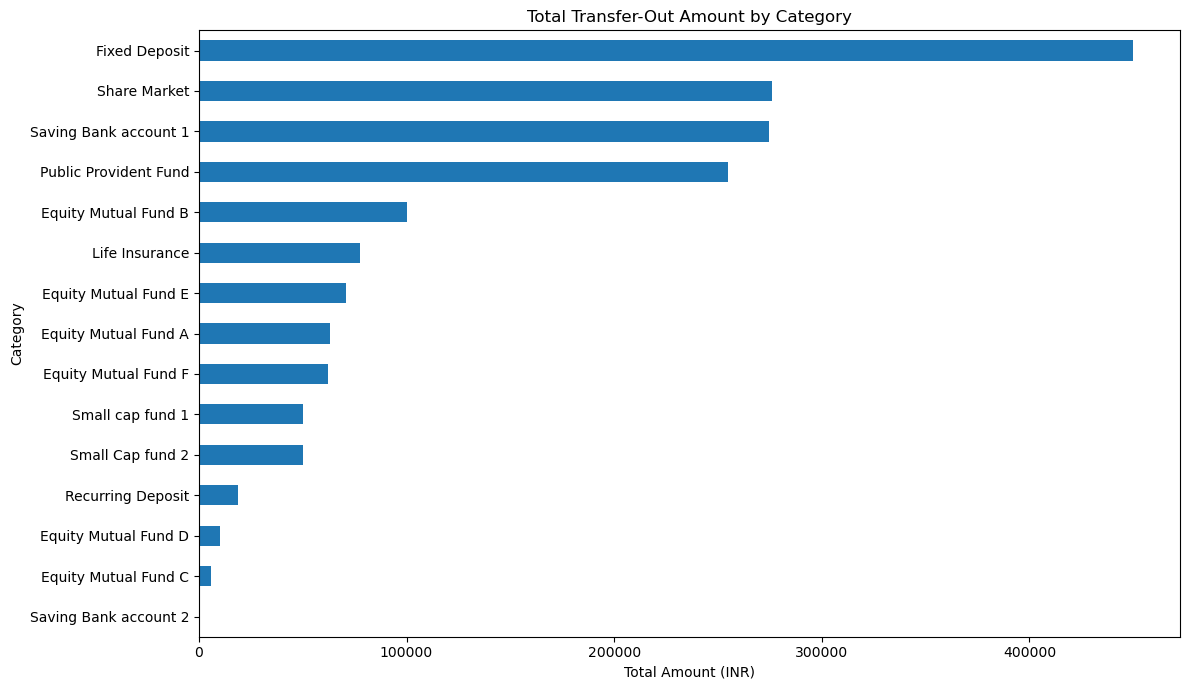

In [14]:
#### 2.3.5 Transfer-Out Amount Visualization


# Create a horizontal bar chart of Transfer-Out amounts.
plt.figure(figsize=(12, 7))

# Sort categories by total transferred amount.
transfer_category_summary["sum"].sort_values().plot(
    kind="barh"
)

# Add chart title and axis labels.
plt.title("Total Transfer-Out Amount by Category")
plt.xlabel("Total Amount (INR)")
plt.ylabel("Category")

# Display the chart.
plt.tight_layout()
plt.show()


In [15]:
### Average transfer amount by category.
# Now I want to investigate something interesting:

# Does a category with more transactions necessarily have a higher average transaction amount?



In [16]:

# Calculate the average transfer amount for each category.
transfer_category_summary["average_amount"] = (
    transfer_category_summary["sum"] /
    transfer_category_summary["count"]
)

# Display transaction count, total amount, and average amount.
print("Average Transfer Amount by Category:")

display(
    transfer_category_summary[
        ["count", "sum", "average_amount"]
    ].sort_values(
        by="average_amount",
        ascending=False
    )
)


Average Transfer Amount by Category:


,count,sum,average_amount
Category,,,
Fixed Deposit,2,450000.00,225000.000000
Equity Mutual Fund B,1,100000.00,100000.000000
Share Market,8,276161.00,34520.125000
Saving Bank account 1,17,274798.57,16164.621765
Public Provident Fund,21,255000.00,12142.857143
Life Insurance,7,77544.00,11077.714286
Equity Mutual Fund D,1,10000.00,10000.000000
Small cap fund 1,10,50000.00,5000.000000
Small Cap fund 2,10,50000.00,5000.000000


In [17]:
#  now we do Category analysis

# Our objective is to understand :-
# Where is the most of the money spent?
# Which category have the highest spending?
#  Which categories have the most transactions?
# How does income differ across categories?


In [18]:
# 3. Category Analysis

## 3.1 Expense Category Analysis

In [19]:

# Select only transactions classified as Expense.
# We exclude Income and Transfer-Out from spending analysis.

expense_df = df[
    df["Income/Expense"] == "Expense"
]

# Display the first five expense transactions.
display(expense_df.head())

# Check the total number of expense transactions.
print("Total Expense Transactions:", len(expense_df))



# we only have to analyse the expenses so we make a df of only expenses.

,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency,DateTime
0,2018-09-20,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR,2018-09-20 12:04:08
1,2018-09-20,Cash,Food,snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR,2018-09-20 12:03:15
2,2018-09-19,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR,2018-09-19 00:00:00
3,2018-09-17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR,2018-09-17 23:41:17
4,2018-09-16,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR,2018-09-16 17:15:08


Total Expense Transactions: 2173


In [20]:
# Now we do Category wise Analysis.

# Which category has the highest number of transaction?
# Which category accounts for the highest spending?
# How much money is spend in each category?
# What is the average transaction amount in each category?

In [21]:
### 3.2 Category-wise Expense Analysis


# Group expense transactions by Category.
# Calculate transaction count, total spending and average spending.

expense_category_summary = (
    expense_df.groupby("Category")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

# Display the category-wise expense summary.
print("Expense Category Analysis:")

display(expense_category_summary)

# so this will show us the total count, sum and mean of expenses of each category.


Expense Category Analysis:


,count,sum,mean
Category,,,
Money transfer,43,606528.90,14105.323256
Investment,101,269858.00,2671.861386
Transportation,307,169053.78,550.663779
Household,176,161645.58,918.440795
subscription,143,114587.91,801.314056
Food,906,96393.10,106.394150
Public Provident Fund,8,90000.00,11250.000000
Other,114,87025.28,763.379649
Family,71,78582.20,1106.791549


In [22]:
# Finding 1: Food has the highest transaction frequency
# 906 transactions
# Food accounts for the largest number of expense transactions.
# This suggests that food-related transactions happen frequently.

# Finding 2: Money transfer has the highest total amount
# ₹6,06,528.90
# Despite having only 43 transactions, Money transfer has the highest total amount.
# This is an important observation.

# Finding 3: Food has relatively small average transactions
# Food has 906 transactions, with an average transaction amount of approximately ₹106.39.
# This suggests frequent, relatively small transactions.

In [23]:
### 3.3 Investigation of Money Transfer Category


# Filter Money transfer transactions from Expense records.
money_transfer_df = expense_df[
    expense_df["Category"] == "Money transfer"
]

# Display important details of these transactions.
print("Money Transfer Transactions:")

display(
    money_transfer_df[
        ["Date", "Mode", "Category", "Subcategory", "Note", "Amount"]
    ].sort_values(
        by="Amount",
        ascending=False
    )
)

# Calculate the total amount and number of transactions.
print("Total Transactions:", len(money_transfer_df))

print(
    "Total Amount:",
    f"₹{money_transfer_df['Amount'].sum():,.2f}"
)


Money Transfer Transactions:


,Date,Mode,Category,Subcategory,Note,Amount
1703,2017-01-01,Saving Bank account 1,Money transfer,Home,No Note,100000.0
2077,2015-01-12,Saving Bank account 1,Money transfer,Home,No Note,50000.0
102,2018-07-31,Saving Bank account 1,Money transfer,Home,No Note,30000.0
672,2018-01-01,Saving Bank account 1,Money transfer,Home,No Note,30000.0
376,2018-06-04,Saving Bank account 1,Money transfer,Home,No Note,24500.0
1924,2016-01-07,Saving Bank account 1,Money transfer,Home,No Note,15000.0
1908,2016-01-08,Saving Bank account 1,Money transfer,Home,No Note,15000.0
394,2018-01-04,Saving Bank account 1,Money transfer,Home,No Note,10005.9
191,2018-01-07,Saving Bank account 1,Money transfer,Home,No Note,10000.0
315,2018-01-05,Saving Bank account 1,Money transfer,Home,No Note,10000.0


Total Transactions: 43
Total Amount: ₹606,528.90


In [24]:
#### 3.3.2 Money Transfer Analysis by Mode and Note


# Analyze Money Transfer transactions by payment mode.
print("Money Transfer by Payment Mode:")

display(
    money_transfer_df.groupby("Mode")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

# Analyze transactions by their notes.
print("\nMoney Transfer by Note:")

display(
    money_transfer_df.groupby("Note")["Amount"]
    .agg(["count", "sum"])
    .sort_values(by="sum", ascending=False)
)

# Display all unique notes.
print("\nUnique Money Transfer Notes:")
print(money_transfer_df["Note"].unique())


Money Transfer by Payment Mode:


,count,sum,mean
Mode,,,
Saving Bank account 1,40,594505.9,14862.6475
Credit Card,1,10000.0,10000.0000
Cash,2,2023.0,1011.5000



Money Transfer by Note:


,count,sum
Note,,
No Note,42,606505.9
To Family,1,23.0



Unique Money Transfer Notes:
['No Note' 'To Family']


In [25]:
# # so our research on money transfer by modes is completed and from thsi we can say that :-
# Money Transfer — Research observations
# Analysis completed
# - Total transactions: 43
# - Total amount: ₹6,06,528.90
# - Predominant mode: Saving Bank account 1
# - Missing descriptive notes: 42
# - Purpose: Not conclusively identifiable



In [26]:
# Now our next step is to investigate our investiment and public profit fund.
# These are currently classified as Expense, but they may represent wealth-building activities rather than ordinary consumption.


In [27]:
### 3.4 Investigation of Financial Activity Categories


# Select financial activity categories from Expense transactions.
financial_activity_df = expense_df[
    expense_df["Category"].isin(
        ["Money transfer", "Investment", "Public Provident Fund"]
    )
]

# Summarize transaction count and amount by category.
financial_activity_summary = (
    financial_activity_df.groupby("Category")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

# Display the results.
print("Financial Activity Category Summary:")
display(financial_activity_summary)

# Investigate the notes associated with these transactions.
print("\nFinancial Activity Notes:")

display(
    financial_activity_df.groupby(
        ["Category", "Note"]
    )["Amount"].agg(["count", "sum"])
)


Financial Activity Category Summary:


,count,sum,mean
Category,,,
Money transfer,43,606528.9,14105.323256
Investment,101,269858.0,2671.861386
Public Provident Fund,8,90000.0,11250.000000



Financial Activity Notes:


count       sum
Category              Note                                        
Investment             mutual fund                     9    9000.0
                      ICICI prudential                10   10000.0
                      Life Insurance                   3   33858.0
                      Mutual fund A                    7    7000.0
                      Mutual fund B                    7    7000.0
                      Mutual fund C                    7    7000.0
                      No Note                         46  184000.0
                      RD                               2    2000.0
                      reliance mutual fund            10   10000.0
Money transfer        No Note                         42  606505.9
                      To Family                        1      23.0
Public Provident Fund April -May 10k contribution      1   20000.0
                      No Note                          7   70000.0

In [28]:
# Now we Investigate Public Provident Fund and remaining investment notes



In [29]:
#### 3.4.1 Detailed Investment and PPF Investigation


# Display all investment notes and their amounts.
investment_only_df = expense_df[
    expense_df["Category"] == "Investment"
]

print("Investment Notes:")

display(
    investment_only_df.groupby("Note")["Amount"]
    .agg(["count", "sum"])
    .sort_values(by="sum", ascending=False)
)

# Display Public Provident Fund transactions.
# .copy() creates an independent DataFrame.
ppf_df = expense_df[
    expense_df["Category"] == "Public Provident Fund"
].copy()

print("\nPublic Provident Fund Transactions:")

display(
    ppf_df[
        ["Date", "Mode", "Subcategory", "Note", "Amount"]
    ]
)

# Summarize PPF transactions.
print("\nPPF Summary:")
print("Transaction Count:", len(ppf_df))
print(f"Total Amount: ₹{ppf_df['Amount'].sum():,.2f}")


Investment Notes:


,count,sum
Note,,
No Note,46,184000.0
Life Insurance,3,33858.0
reliance mutual fund,10,10000.0
ICICI prudential,10,10000.0
mutual fund,9,9000.0
Mutual fund B,7,7000.0
Mutual fund A,7,7000.0
Mutual fund C,7,7000.0
RD,2,2000.0



Public Provident Fund Transactions:


,Date,Mode,Subcategory,Note,Amount
2078,2015-01-12,Saving Bank account 1,Unknown,No Note,10000.0
2098,2015-04-11,Cash,Unknown,No Note,10000.0
2131,2015-01-10,Saving Bank account 1,Unknown,No Note,10000.0
2147,2015-01-09,Saving Bank account 1,Unknown,No Note,10000.0
2162,2015-02-08,Saving Bank account 1,Unknown,No Note,10000.0
2177,2015-01-07,Saving Bank account 1,Unknown,No Note,10000.0
2189,2015-01-06,Saving Bank account 1,Unknown,No Note,10000.0
2217,2015-03-05,Saving Bank account 1,Unknown,April -May 10k contribution,20000.0



PPF Summary:
Transaction Count: 8
Total Amount: ₹90,000.00


In [30]:
# # Why this step?
# We want to understand whether the PPF transactions are consistently recorded and whether their notes provide additional information.


In [31]:
#### 3.4.2 PPF Payment Mode Analysis


# Analyze PPF transactions by payment mode.
print("PPF Transactions by Payment Mode:")

display(
    ppf_df.groupby("Mode")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

# Analyze PPF transactions over time.
print("\nPPF Transactions by Year:")

ppf_df["Year"] = ppf_df["Date"].dt.year

display(
    ppf_df.groupby("Year")["Amount"]
    .agg(["count", "sum"])
)


PPF Transactions by Payment Mode:


,count,sum,mean
Mode,,,
Saving Bank account 1,7,80000.0,11428.571429
Cash,1,10000.0,10000.000000



PPF Transactions by Year:


,count,sum
Year,,
2015,8,90000.0


In [32]:
# What next ? 

# In real-life personal finance, putting money into a savings scheme is not the same as spending money on groceries or electricity. 
# If we feed raw "Expense" data into ForeSight's future Machine Learning models, the forecasting model will treat investments 
# as household spending, and the nudge engine might warn a user that they are "overspending" during months when they actually saved 
# more money. Creating a clean separation between wealth-building/transfers and true household consumption ensures our ML features are financially accurate.

In [33]:
### 3.5 Household Consumption Analysis
#### 3.5.1 Preliminary Consumption Candidate Filtering

# Define the financial categories we have already identified and investigated.
financial_categories = [
    "Money transfer",
    "Investment",
    "Public Provident Fund"
]

# Create a preliminary DataFrame excluding these three financial categories.
# We use .copy() to create an independent DataFrame and avoid SettingWithCopyWarning.
consumption_candidate_df = expense_df[
    ~expense_df["Category"].isin(financial_categories)
].copy()

# Verify the remaining transaction count and total amount.
print("Preliminary Consumption Candidate Transactions:", len(consumption_candidate_df))
print(
    "Preliminary Consumption Candidate Total Amount:",
    f"₹{consumption_candidate_df['Amount'].sum():,.2f}"
)

# Summarize the remaining categories to inspect if any other financial activities remain.
print("\nRemaining Categories in Consumption Candidate DataFrame:")

display(
    consumption_candidate_df.groupby("Category")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

Preliminary Consumption Candidate Transactions: 2021
Preliminary Consumption Candidate Total Amount: ₹988,993.63

Remaining Categories in Consumption Candidate DataFrame:


,count,sum,mean
Category,,,
Transportation,307,169053.78,550.663779
Household,176,161645.58,918.440795
subscription,143,114587.91,801.314056
Food,906,96393.10,106.394150
Other,114,87025.28,763.379649
Family,71,78582.20,1106.791549
Health,94,66252.75,704.816489
Tourism,5,63608.85,12721.770000
Gift,30,40168.00,1338.933333


In [34]:
df

,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency,DateTime
0,2018-09-20,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR,2018-09-20 12:04:08
1,2018-09-20,Cash,Food,snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR,2018-09-20 12:03:15
2,2018-09-19,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR,2018-09-19 00:00:00
3,2018-09-17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR,2018-09-17 23:41:17
4,2018-09-16,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR,2018-09-16 17:15:08
...,...,...,...,...,...,...,...,...,...
2447,2015-01-01,Cash,Transportation,auto,share jeep - Place T base to top,20.0,Expense,INR,2015-01-01 00:00:00
2448,2015-01-01,Cash,Transportation,auto,share auto - Place H to Place T base,20.0,Expense,INR,2015-01-01 00:00:00
2449,2015-01-01,Cash,Transportation,auto,bus - brc to Place H,30.0,Expense,INR,2015-01-01 00:00:00
2450,2015-01-01,Cash,Food,Milk,tea,10.0,Expense,INR,2015-01-01 00:00:00


In [35]:
#### 3.5.2 Investigation of Recurring Deposit in Expense Records

# Filter Recurring Deposit transactions from our consumption candidate DataFrame.
# We use .copy() so we can safely add a Year column for time inspection.
rd_expense_df = consumption_candidate_df[
    consumption_candidate_df["Category"] == "Recurring Deposit"
].copy()

# Display transaction count and total amount.
print("Recurring Deposit (in Expenses) Transaction Count:", len(rd_expense_df))
print(
    "Recurring Deposit (in Expenses) Total Amount:",
    f"₹{rd_expense_df['Amount'].sum():,.2f}"
)

# Analyze Recurring Deposit transactions by Payment Mode.
print("\nRecurring Deposit by Payment Mode:")
display(
    rd_expense_df.groupby("Mode")["Amount"]
    .agg(["count", "sum", "mean"])
)

# Analyze Recurring Deposit transactions by Subcategory and Note.
print("\nRecurring Deposit by Subcategory and Note:")
display(
    rd_expense_df.groupby(["Subcategory", "Note"])["Amount"]
    .agg(["count", "sum"])
)

# Check which years these Recurring Deposit transactions were recorded as Expenses.
rd_expense_df["Year"] = rd_expense_df["Date"].dt.year

print("\nRecurring Deposit (in Expenses) by Year:")
display(
    rd_expense_df.groupby("Year")["Amount"]
    .agg(["count", "sum"])
)

Recurring Deposit (in Expenses) Transaction Count: 22
Recurring Deposit (in Expenses) Total Amount: ₹22,000.00

Recurring Deposit by Payment Mode:


,count,sum,mean
Mode,,,
Saving Bank account 1,22,22000.0,1000.0



Recurring Deposit by Subcategory and Note:


,,count,sum
Subcategory,Note,,
Unknown,No Note,22,22000.0



Recurring Deposit (in Expenses) by Year:


,count,sum
Year,,
2015,20,20000.0
2016,2,2000.0


In [36]:
# Now we are going to analyse two categories "other" and "family".
# Why it is used: If we blindly include "Other" in household consumption without checking its Subcategory and Note columns,
# there might be hidden investments, loan repayments, or bank transfers inside that ₹87,025.28. Conversely, 
# if "Other" contains things like subscriptions, snacks, or shopping, then it truly belongs in household consumption.

In [37]:
#### 3.5.3 Inspecting Ambiguous Categories ("Other" and "Family")

# 1. Inspect the "Other" category by Subcategory and top Notes.
other_expense_df = consumption_candidate_df[
    consumption_candidate_df["Category"] == "Other"
]

print("Top 15 'Other' Category Transactions by Subcategory and Note:")
display(
    other_expense_df.groupby(["Subcategory", "Note"])["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
    .head(15)
)

# 2. Inspect the "Family" category by Subcategory and top Notes.
family_expense_df = consumption_candidate_df[
    consumption_candidate_df["Category"] == "Family"
]

print("\nTop 15 'Family' Category Transactions by Subcategory and Note:")
display(
    family_expense_df.groupby(["Subcategory", "Note"])["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
    .head(15)
)

Top 15 'Other' Category Transactions by Subcategory and Note:


count      sum  \
Subcategory Note                                                        
Unknown     Permanent Residence money transfer             2  20000.0   
            Public Provident Fund                          1  10000.0   
            Shopping at Alfa                               2   8410.0   
            splitwise settlement                           3   5037.0   
            Internet renewal                               3   4400.0   
            CA  - income tax filing                        2   3000.0   
            internet renewal (3 months pack)               2   2900.0   
            rent                                           1   2833.0   
            Mobile Service Provider recharge 365 days      1   2599.0   
            cook                                           1   2250.0   
            Mobile Service Provider fi router              1   2099.0   
            laptop table                                   1   1994.0   
            ipad cover + case                              1   1888.0   
            specs                                          1   1780.0   
            Fifa 21 pc                                     1   1499.0   

                                                               mean  
Subcategory Note                                                     
Unknown     Permanent Residence money transfer         10000.000000  
            Public Provident Fund                      10000.000000  
            Shopping at Alfa                            4205.000000  
            splitwise settlement                        1679.000000  
            Internet renewal                            1466.666667  
            CA  - income tax filing                     1500.000000  
            internet renewal (3 months pack)            1450.000000  
            rent                                        2833.000000  
            Mobile Service Provider recharge 365 days   2599.000000  
            cook                                        2250.000000  
            Mobile Service Provider fi router           2099.000000  
            laptop table                                1994.000000  
            ipad cover + case                           1888.000000  
            specs                                       1780.000000  
            Fifa 21 pc                                  1499.000000


Top 15 'Family' Category Transactions by Subcategory and Note:


count      sum    mean
Subcategory  Note                                                           
Pocket money No Note                                     47  58045.0  1235.0
clothes      No Note                                      1   3598.0  3598.0
             Fab India                                    1   3198.0  3198.0
misc         Family Mobile Service Provider recharge      1   2599.0  2599.0
clothes      sweater                                      1   1874.0  1874.0
             H&M clothes                                  1   1497.0  1497.0
gift         Undated Planner - June shop                  1   1119.2  1119.2
exam fee     Family exam form                             1    905.0   905.0
clothes      Trouser                                      1    799.0   799.0
exam fee     PET Psychology                               1    750.0   750.0
makeup       Body mist                                    1    525.0   525.0
clothes      leggings                                     1    500.0   500.0
misc         scratch guard ipad                           2    498.0   249.0
clothes      Belt + bow                                   1    498.0   498.0
misc         For utensils                                 1    450.0   450.0

In [38]:
#### 3.5.4 Finalizing Household Consumption Dataset

# Define the complete list of non-consumption financial categories to exclude,
# plus we explicitly filter out the stray PPF transaction found inside "Other".
financial_categories_strict = [
    "Money transfer",
    "Investment",
    "Public Provident Fund"
]

# Create the clean household consumption DataFrame
household_consumption_df = consumption_candidate_df[
    (~consumption_candidate_df["Category"].isin(financial_categories_strict)) &
    (consumption_candidate_df["Note"] != "Public Provident Fund")
].copy()

# Calculate total and average household consumption metrics
total_consumption_count = len(household_consumption_df)
total_consumption_amount = household_consumption_df["Amount"].sum()
avg_consumption_amount = household_consumption_df["Amount"].mean()

print("FINAL HOUSEHOLD CONSUMPTION OVERVIEW")
print("-" * 40)
print(f"Total Consumption Transactions : {total_consumption_count:,}")
print(f"Total Household Consumption    : ₹{total_consumption_amount:,.2f}")
print(f"Average Transaction Amount     : ₹{avg_consumption_amount:,.2f}")

# Display top 10 final consumption categories by total amount
print("\nTop Household Consumption Categories:")
display(
    household_consumption_df.groupby("Category")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
    .head(10)
)

FINAL HOUSEHOLD CONSUMPTION OVERVIEW
----------------------------------------
Total Consumption Transactions : 2,020
Total Household Consumption    : ₹978,993.63
Average Transaction Amount     : ₹484.65

Top Household Consumption Categories:


,count,sum,mean
Category,,,
Transportation,307,169053.78,550.663779
Household,176,161645.58,918.440795
subscription,143,114587.91,801.314056
Food,906,96393.10,106.394150
Family,71,78582.20,1106.791549
Other,113,77025.28,681.639646
Health,94,66252.75,704.816489
Tourism,5,63608.85,12721.770000
Gift,30,40168.00,1338.933333


In [39]:
df

,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency,DateTime
0,2018-09-20,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR,2018-09-20 12:04:08
1,2018-09-20,Cash,Food,snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR,2018-09-20 12:03:15
2,2018-09-19,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR,2018-09-19 00:00:00
3,2018-09-17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR,2018-09-17 23:41:17
4,2018-09-16,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR,2018-09-16 17:15:08
...,...,...,...,...,...,...,...,...,...
2447,2015-01-01,Cash,Transportation,auto,share jeep - Place T base to top,20.0,Expense,INR,2015-01-01 00:00:00
2448,2015-01-01,Cash,Transportation,auto,share auto - Place H to Place T base,20.0,Expense,INR,2015-01-01 00:00:00
2449,2015-01-01,Cash,Transportation,auto,bus - brc to Place H,30.0,Expense,INR,2015-01-01 00:00:00
2450,2015-01-01,Cash,Food,Milk,tea,10.0,Expense,INR,2015-01-01 00:00:00


In [40]:
# What are we doing next ?

# We know the highest spending categories , but category labels are often too broad . to make foresight an intelligent ai , 
# it need to understand special financial behavior In this step , we will group the data by both Category and subcategory.
# to find out what is exactly inside food and transport is costing so much money.

In [41]:
### 3.6 Category and Subcategory Analysis
#### 3.6.1 Top Spending Subcategories Overall

# Group by both Category and Subcategory to see detailed behavioral spending
subcategory_summary = (
    household_consumption_df.groupby(["Category", "Subcategory"])["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

print("Top 15 Highest Spending Subcategories (Overall):")
display(subcategory_summary.head(15))


#### 3.6.2 Deep Dive into the Top Category: Transportation
# Let's find out exactly what is making Transportation our #1 expense
transport_df = household_consumption_df[
    household_consumption_df["Category"] == "Transportation"
]

print("\nTransportation Spending Breakdown:")
display(
    transport_df.groupby("Subcategory")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)


Top 15 Highest Spending Subcategories (Overall):


,,count,sum,mean
Category,Subcategory,,,
Transportation,Bike,12,94593.00,7882.750000
Household,Appliances,29,82081.00,2830.379310
Other,Unknown,113,77025.28,681.639646
subscription,Edtech Course,14,63733.42,4552.387143
Tourism,Trip,4,63300.00,15825.000000
Family,Pocket money,49,58195.00,1187.653061
Household,Kirana,86,40241.58,467.925349
Gift,Unknown,30,40168.00,1338.933333
Transportation,Travels,19,32338.98,1702.051579



Transportation Spending Breakdown:


,count,sum,mean
Subcategory,,,
Bike,12,94593.00,7882.750000
Travels,19,32338.98,1702.051579
Taxi,19,16140.00,849.473684
train,19,11410.80,600.568421
auto,166,8995.00,54.186747
Bus,15,3228.00,215.200000
Train,55,1650.00,30.000000
Petrol,1,360.00,360.000000
ropeway,1,338.00,338.000000


In [42]:
#### 3.6.3 Refining Household Consumption & Fixing Subcategory Case Sensitivity

# 1. Include "Recurring Deposit" in our strict financial exclusion list
financial_categories_strict = [
    "Money transfer",
    "Investment",
    "Public Provident Fund",
    "Recurring Deposit"
]

# 2. Exclude non-consumption notes ("Public Provident Fund" and "Permanent Residence money transfer")
excluded_notes = [
    "Public Provident Fund",
    "Permanent Residence money transfer"
]

# Recreate household_consumption_df with the complete exclusions
household_consumption_df = expense_df[
    (~expense_df["Category"].isin(financial_categories_strict)) &
    (~expense_df["Note"].isin(excluded_notes))
].copy()

# 3. Standardize Subcategory text (strip extra spaces and convert to Title Case)
# This merges 'train' and 'Train' into a single 'Train' subcategory.
household_consumption_df["Subcategory"] = (
    household_consumption_df["Subcategory"]
    .astype(str)
    .str.strip()
    .str.title()
)

# Verify the updated clean consumption totals
print("REFINED HOUSEHOLD CONSUMPTION OVERVIEW")
print("-" * 42)
print(f"Refined Consumption Transactions : {len(household_consumption_df):,}")
print(f"Refined Household Consumption    : ₹{household_consumption_df['Amount'].sum():,.2f}")

# Re-check Transportation breakdown to confirm 'Train' and 'train' are merged
print("\nCleaned Transportation Spending Breakdown:")
display(
    household_consumption_df[household_consumption_df["Category"] == "Transportation"]
    .groupby("Subcategory")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

REFINED HOUSEHOLD CONSUMPTION OVERVIEW
------------------------------------------
Refined Consumption Transactions : 1,996
Refined Household Consumption    : ₹936,993.63

Cleaned Transportation Spending Breakdown:


,count,sum,mean
Subcategory,,,
Bike,12,94593.00,7882.750000
Travels,19,32338.98,1702.051579
Taxi,19,16140.00,849.473684
Train,74,13060.80,176.497297
Auto,166,8995.00,54.186747
Bus,15,3228.00,215.200000
Petrol,1,360.00,360.000000
Ropeway,1,338.00,338.000000


In [43]:
#### 3.6.4 Deep Dive into Food and Household Categories

# 1. Analyze Food - The most frequent expense
food_df = household_consumption_df[
    household_consumption_df["Category"] == "Food"
]

print("Food Spending Breakdown:")
display(
    food_df.groupby("Subcategory")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

# 2. Analyze Household - The 2nd highest expense by total amount
household_df = household_consumption_df[
    household_consumption_df["Category"] == "Household"
]

print("\nHousehold Spending Breakdown:")
display(
    household_df.groupby("Subcategory")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

Food Spending Breakdown:


,count,sum,mean
Subcategory,,,
Dinner,55,22903.10,416.420000
Grocery,113,17983.80,159.148673
Milk,247,17333.00,70.174089
Lunch,68,11390.45,167.506618
Snacks,115,5980.75,52.006522
Fruits,28,4520.00,161.428571
Eating Out,8,2868.00,358.500000
Flour Mill,20,2007.00,100.350000
Ice Cream,36,1840.00,51.111111



Household Spending Breakdown:


,count,sum,mean
Subcategory,,,
Appliances,29,82081.00,2830.379310
Kirana,86,40241.58,467.925349
Kitchen,23,16349.00,710.826087
Hardware,14,9606.00,686.142857
Home Decor,4,6846.00,1711.500000
Furniture,3,3469.00,1156.333333
Toiletries,14,2254.00,161.000000
Gadgets,3,799.00,266.333333


In [44]:
# To eventually build a Spending Forecasting machine learning model 
# (like ARIMA or Random Forest Regression), we must first aggregate our data into time steps—specifically, months.
# We will group our cleaned household_consumption_df and our original Income transactions by month to see the true monthly cash flow and savings rate.

In [45]:
### 3.7 Time-Based Financial Analysis
#### 3.7.1 Monthly Cash Flow (Income vs. True Consumption)

# 1. Add a 'YearMonth' column to our clean household consumption data
household_consumption_df["YearMonth"] = household_consumption_df["Date"].dt.to_period("M")

# Calculate total consumption per month
monthly_spending = (
    household_consumption_df.groupby("YearMonth")["Amount"]
    .sum()
    .reset_index()
    .rename(columns={"Amount": "Consumption_Amount"})
)

# 2. Extract Income data and group it by month
income_df = df[df["Income/Expense"] == "Income"].copy()
income_df["YearMonth"] = income_df["Date"].dt.to_period("M")

monthly_income = (
    income_df.groupby("YearMonth")["Amount"]
    .sum()
    .reset_index()
    .rename(columns={"Amount": "Income_Amount"})
)

# 3. Merge Income and Consumption to see the monthly cash flow
monthly_cashflow = pd.merge(
    monthly_income, 
    monthly_spending, 
    on="YearMonth", 
    how="outer" # Outer join ensures we include months that only had expenses or only had income
).fillna(0) # Fill NaN with 0 for months missing income or expenses

# Calculate True Savings (Income - Consumption)
monthly_cashflow["True_Savings"] = (
    monthly_cashflow["Income_Amount"] - monthly_cashflow["Consumption_Amount"]
)

# Sort chronologically
monthly_cashflow = monthly_cashflow.sort_values(by="YearMonth").reset_index(drop=True)

print("Monthly Cash Flow and True Savings Trend:")
display(monthly_cashflow)

Monthly Cash Flow and True Savings Trend:


,YearMonth,Income_Amount,Consumption_Amount,True_Savings
0,2015-01,0.00,15144.00,-15144.00
1,2015-02,49806.00,18919.00,30887.00
2,2015-03,70806.00,19253.80,51552.20
3,2015-04,54106.00,4806.00,49300.00
4,2015-05,47859.00,17603.00,30256.00
5,2015-06,47859.00,1343.00,46516.00
6,2015-07,47859.00,11115.00,36744.00
7,2015-08,49806.00,9624.00,40182.00
8,2015-09,49806.00,5185.00,44621.00
9,2015-10,49806.00,8604.60,41201.40


In [46]:
# We need to understand how the user pays for their household consumption. We will group the household_consumption_df by the Mode column to see 
# the preference between Cash, Bank Accounts, and Credit Cards. Then, we will take it a step further and see what exactly 
# they are buying with Cash versus Credit Cards.

In [47]:
### 3.8 Payment Mode Analysis
#### 3.8.1 Overall Payment Mode Preferences for Consumption

print("Household Consumption by Payment Mode:")
display(
    household_consumption_df.groupby("Mode")["Amount"]
    .agg(["count", "sum", "mean"])
    .sort_values(by="sum", ascending=False)
)

#### 3.8.2 What do they buy with Cash vs. Credit Card?

# 1. Isolate Cash transactions and check top categories
cash_df = household_consumption_df[household_consumption_df["Mode"] == "Cash"]

print("\nTop 5 Categories Paid in Cash:")
display(
    cash_df.groupby("Category")["Amount"]
    .agg(["count", "sum"])
    .sort_values(by="sum", ascending=False)
    .head(5)
)

# 2. Isolate Credit Card transactions and check top categories
cc_df = household_consumption_df[household_consumption_df["Mode"] == "Credit Card"]

print("\nTop 5 Categories Paid with Credit Card:")
display(
    cc_df.groupby("Category")["Amount"]
    .agg(["count", "sum"])
    .sort_values(by="sum", ascending=False)
    .head(5)
)

Household Consumption by Payment Mode:


,count,sum,mean
Mode,,,
Saving Bank account 1,796,579364.56,727.844925
Credit Card,161,195254.01,1212.757826
Cash,1035,161398.00,155.940097
Debit Card,2,942.36,471.180000
Saving Bank account 2,2,34.70,17.350000



Top 5 Categories Paid in Cash:


,count,sum
Category,,
Food,482,33289.0
maid,15,21173.0
Family,39,20910.0
Household,87,19793.0
Transportation,241,15065.0



Top 5 Categories Paid with Credit Card:


,count,sum
Category,,
subscription,24,40538.49
Health,12,39302.75
Household,41,38866.90
Food,41,18608.40
Apparel,10,14882.82


In [48]:
### 3.9 Spending Pattern and Anomaly Analysis
#### 3.9.1 Identifying the Largest Single Transactions (The "Whales")

print("Top 10 Largest Single Consumption Transactions:")
display(
    household_consumption_df.nlargest(10, "Amount")[
        ["Date", "Category", "Subcategory", "Mode", "Note", "Amount"]
    ]
)

#### 3.9.2 Statistical Outlier Detection (99th Percentile)

# Calculate the 99th percentile threshold for household consumption
outlier_threshold = household_consumption_df["Amount"].quantile(0.99)

print(f"\n99th Percentile Threshold: ₹{outlier_threshold:,.2f}")
print("Transactions above this threshold are statistically unusual (Outliers).")

# Filter the DataFrame to find these rare, high-value outliers
outliers_df = household_consumption_df[
    household_consumption_df["Amount"] > outlier_threshold
]

print(f"\nFound {len(outliers_df)} outlier transactions:")
display(
    outliers_df.sort_values(by="Amount", ascending=False)[
        ["Date", "Category", "Subcategory", "Mode", "Note", "Amount"]
    ]
)

Top 10 Largest Single Consumption Transactions:


,Date,Category,Subcategory,Mode,Note,Amount
608,2018-01-18,Transportation,Bike,Saving Bank account 1,Two Wheeler Bikedelux second installment,50000.0
582,2018-01-27,Transportation,Bike,Saving Bank account 1,Two Wheeler Bikedelux third installment,43000.0
1076,2017-08-08,Tourism,Trip,Saving Bank account 1,Tours and Travel,43000.0
706,2017-12-20,subscription,Edtech Course,Credit Card,Renewal,28400.0
770,2017-11-30,Health,Health,Credit Card,Family's Glasses,22700.0
268,2018-05-15,Household,Appliances,Saving Bank account 1,LG Washing Machine,21500.0
1773,2016-11-28,Household,Appliances,Saving Bank account 1,Metz 32 inch TV,20500.0
1132,2017-07-25,Tourism,Trip,Saving Bank account 1,Tours and Travel,20000.0
218,2018-06-26,Household,Appliances,Saving Bank account 1,Aqugurad water purifier,13050.0
1395,2017-03-05,Household,Kitchen,Saving Bank account 1,Gas stove elica 3 burner,8825.0



99th Percentile Threshold: ₹5,000.00
Transactions above this threshold are statistically unusual (Outliers).

Found 18 outlier transactions:


,Date,Category,Subcategory,Mode,Note,Amount
608,2018-01-18,Transportation,Bike,Saving Bank account 1,Two Wheeler Bikedelux second installment,50000.0
582,2018-01-27,Transportation,Bike,Saving Bank account 1,Two Wheeler Bikedelux third installment,43000.0
1076,2017-08-08,Tourism,Trip,Saving Bank account 1,Tours and Travel,43000.0
706,2017-12-20,subscription,Edtech Course,Credit Card,Renewal,28400.0
770,2017-11-30,Health,Health,Credit Card,Family's Glasses,22700.0
268,2018-05-15,Household,Appliances,Saving Bank account 1,LG Washing Machine,21500.0
1773,2016-11-28,Household,Appliances,Saving Bank account 1,Metz 32 inch TV,20500.0
1132,2017-07-25,Tourism,Trip,Saving Bank account 1,Tours and Travel,20000.0
218,2018-06-26,Household,Appliances,Saving Bank account 1,Aqugurad water purifier,13050.0
1395,2017-03-05,Household,Kitchen,Saving Bank account 1,Gas stove elica 3 burner,8825.0


C:\Users\singh\AppData\Local\Temp\ipykernel_16724\2095316550.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


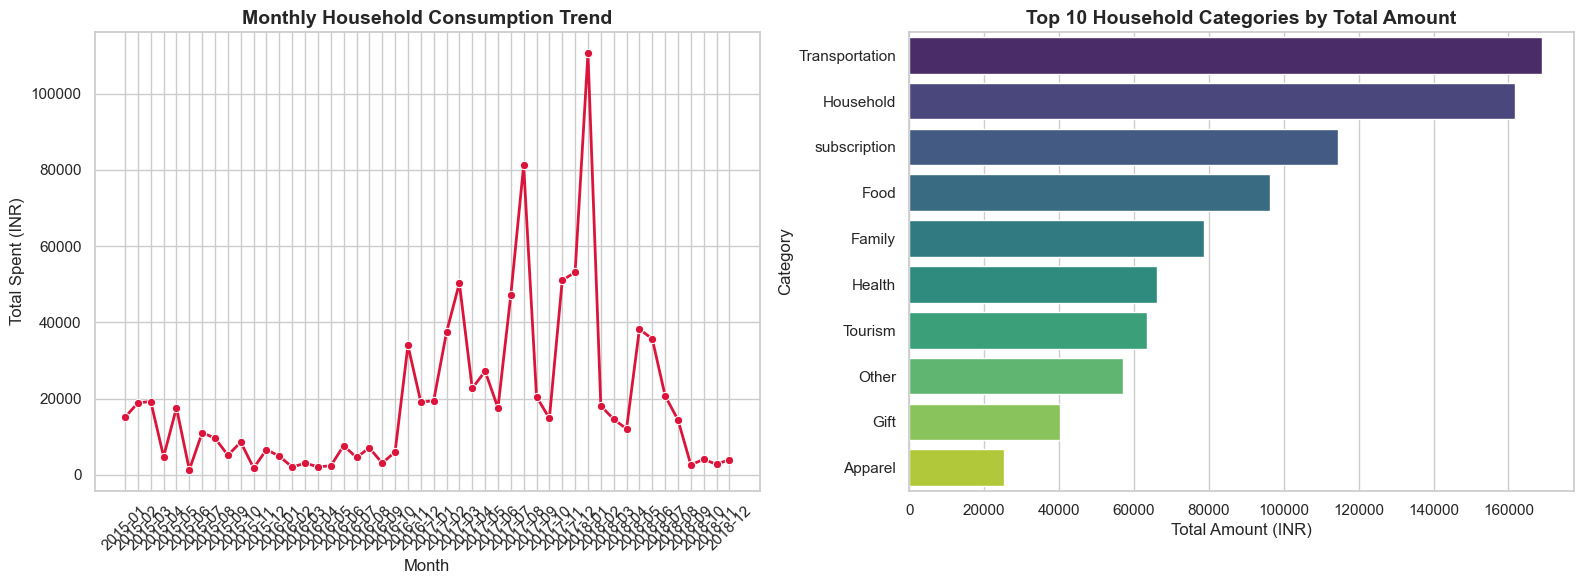

In [49]:
### 3.10 Data Visualization
#### 3.10.1 Household Financial Dashboard

import matplotlib.pyplot as plt
import seaborn as sns

# Set the visualization style
sns.set_theme(style="whitegrid")

# Create a figure with two subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- CHART 1: Monthly Consumption Trend ---
# Convert YearMonth back to string format so matplotlib can plot it easily
monthly_cashflow["YearMonth_Str"] = monthly_cashflow["YearMonth"].astype(str)

sns.lineplot(
    data=monthly_cashflow, 
    x="YearMonth_Str", 
    y="Consumption_Amount", 
    ax=axes[0], 
    marker="o", 
    color="crimson",
    linewidth=2
)

axes[0].set_title("Monthly Household Consumption Trend", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Month", fontsize=12)
axes[0].set_ylabel("Total Spent (INR)", fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# --- CHART 2: Top 10 Spending Categories ---
top_categories = (
    household_consumption_df.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

sns.barplot(
    data=top_categories,
    x="Amount",
    y="Category",
    ax=axes[1],
    palette="viridis"
)

axes[1].set_title("Top 10 Household Categories by Total Amount", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Total Amount (INR)", fontsize=12)
axes[1].set_ylabel("Category", fontsize=12)

# Adjust layout so labels don't overlap and show the plots
plt.tight_layout()
plt.show()

In [50]:
### 3.12 Machine Learning Preparation
#### 3.12.1 Feature Engineering for Expense Classification

# We want to train an AI to automatically predict the "Category" of a new transaction.
# Let's create a specific DataFrame just for this classification task.
ml_classification_df = household_consumption_df[["Date", "Mode", "Amount", "Category"]].copy()

# Feature 1: Time behavior (Extract Day of Week and Month)
# 0 = Monday, 6 = Sunday. People spend differently on weekends vs weekdays!
ml_classification_df["DayOfWeek"] = ml_classification_df["Date"].dt.dayofweek
ml_classification_df["Month"] = ml_classification_df["Date"].dt.month

# Feature 2: Payment Mode (Machine Learning needs numbers, not text)
# We use Pandas get_dummies (One-Hot Encoding) to turn "Cash" and "Credit Card" into True/False (1s and 0s)
ml_classification_df = pd.get_dummies(ml_classification_df, columns=["Mode"], drop_first=False)

# Drop the original Date column since we have extracted the useful numeric parts
ml_classification_df = ml_classification_df.drop(columns=["Date"])

print("Machine Learning Classification Dataset (First 5 Rows):")
display(ml_classification_df.head())

Machine Learning Classification Dataset (First 5 Rows):


,Amount,Category,DayOfWeek,Month,Mode_Cash,Mode_Credit Card,Mode_Debit Card,Mode_Saving Bank account 1,Mode_Saving Bank account 2
0,30.0,Transportation,3,9,True,False,False,False,False
1,60.0,Food,3,9,True,False,False,False,False
2,199.0,subscription,2,9,False,False,False,True,False
3,19.0,subscription,0,9,False,False,False,True,False
4,251.0,Festivals,6,9,True,False,False,False,False


In [51]:
# Ml part :- 


In [52]:
# Section 3.12.2 — Category Distribution

# Count how many transactions belong to each category.
category_counts = ml_classification_df["Category"].value_counts()

# Display the category counts.
print("Category Distribution:")
display(category_counts)

# Display the percentage of each category.
print("\nCategory Percentage:")
display(
    (category_counts / len(ml_classification_df) * 100).round(2)
)

# Check the smallest category size.
print("\nSmallest category size:", category_counts.min())

Category Distribution:


Category
Food                   906
Transportation         307
Household              176
subscription           143
Other                  111
Health                  94
Family                  71
Apparel                 47
Gift                    30
Beauty                  22
Education               18
maid                    17
Festivals               16
Culture                 11
Tourism                  5
Cook                     4
Grooming                 4
Rent                     4
water (jar /tanker)      3
Self-development         2
Documents                2
garbage disposal         2
Social Life              1
Name: count, dtype: int64


Category Percentage:


Category
Food                   45.39
Transportation         15.38
Household               8.82
subscription            7.16
Other                   5.56
Health                  4.71
Family                  3.56
Apparel                 2.35
Gift                    1.50
Beauty                  1.10
Education               0.90
maid                    0.85
Festivals               0.80
Culture                 0.55
Tourism                 0.25
Cook                    0.20
Grooming                0.20
Rent                    0.20
water (jar /tanker)     0.15
Self-development        0.10
Documents               0.10
garbage disposal        0.10
Social Life             0.05
Name: count, dtype: float64


Smallest category size: 1


In [53]:
# Section 3.12.3 — Preparing Training and Testing Data

# Separate input features (X) and target variable (y)
X = ml_classification_df.drop(columns=["Category"])
y = ml_classification_df["Category"]

# Display the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget categories:")
print(y.nunique())

Features shape: (1996, 8)
Target shape: (1996,)

Feature columns:
['Amount', 'DayOfWeek', 'Month', 'Mode_Cash', 'Mode_Credit Card', 'Mode_Debit Card', 'Mode_Saving Bank account 1', 'Mode_Saving Bank account 2']

Target categories:
23


In [54]:
# Check categories with very few transactions

print("Categories with fewer than 2 transactions:")

display(category_counts[category_counts < 2])

print("\nCategories with fewer than 5 transactions:")

display(category_counts[category_counts < 5])

print("\nMinimum category count:", category_counts.min())

Categories with fewer than 2 transactions:


Category
Social Life    1
Name: count, dtype: int64


Categories with fewer than 5 transactions:


Category
Cook                   4
Grooming               4
Rent                   4
water (jar /tanker)    3
Self-development       2
Documents              2
garbage disposal       2
Social Life            1
Name: count, dtype: int64


Minimum category count: 1


In [55]:
from sklearn.model_selection import train_test_split

# Identify categories with only one transaction
rare_categories = category_counts[category_counts < 2].index

# Separate rare category transactions
rare_mask = y.isin(rare_categories)

X_rare = X[rare_mask]
y_rare = y[rare_mask]

# Separate remaining transactions
X_common = X[~rare_mask]
y_common = y[~rare_mask]

# Split remaining data using stratification
X_train, X_test, y_train, y_test = train_test_split(
    X_common,
    y_common,
    test_size=0.20,
    random_state=42,
    stratify=y_common
)

# Add rare transactions to training data
X_train = pd.concat([X_train, X_rare])
y_train = pd.concat([y_train, y_rare])

# Display final dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nSocial Life transactions in training:", 
      (y_train == "Social Life").sum())

print("Social Life transactions in testing:", 
      (y_test == "Social Life").sum())

Training features: (1597, 8)
Testing features: (399, 8)
Training target: (1597,)
Testing target: (399,)

Social Life transactions in training: 1
Social Life transactions in testing: 0


In [56]:
# Section 3.12.4 — Random Forest Classification

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model using training data
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [57]:
# Section 3.12.5 — Generate Model Predictions

# Predict expense categories using testing data
y_pred = rf_model.predict(X_test)

# Display the first 10 actual and predicted categories
results_df = pd.DataFrame({
    "Actual Category": y_test.values,
    "Predicted Category": y_pred
})

display(results_df.head(10))

,Actual Category,Predicted Category
0,Household,Household
1,Household,Household
2,Festivals,Transportation
3,Food,Education
4,Food,Food
5,Transportation,Transportation
6,Food,Food
7,Food,Food
8,Transportation,Transportation
9,subscription,Transportation


In [58]:
# Section 3.12.6 — Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Calculate overall accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Model Accuracy:", round(accuracy * 100, 2), "%")

# Display detailed classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Random Forest Model Accuracy: 46.37 %

Classification Report:
                     precision    recall  f1-score   support

            Apparel       0.20      0.22      0.21         9
             Beauty       0.00      0.00      0.00         4
               Cook       0.00      0.00      0.00         1
            Culture       1.00      0.50      0.67         2
          Education       0.00      0.00      0.00         4
             Family       0.23      0.21      0.22        14
          Festivals       0.00      0.00      0.00         3
               Food       0.61      0.66      0.63       181
               Gift       0.00      0.00      0.00         6
           Grooming       0.00      0.00      0.00         1
             Health       0.27      0.21      0.24        19
          Household       0.31      0.23      0.26        35
              Other       0.18      0.09      0.12        22
               Rent       0.00      0.00      0.00         1
        Social Life   

In [59]:
# Section 3.12.7 — Category Label Inspection

print("Unique category labels:")

display(
    ml_classification_df["Category"]
    .value_counts()
    .sort_index()
)

print("\nCategory labels with leading or trailing spaces:")

display(
    ml_classification_df[
        ml_classification_df["Category"] !=
        ml_classification_df["Category"].str.strip()
    ]["Category"].unique()
)

Unique category labels:


Category
Apparel                 47
Beauty                  22
Cook                     4
Culture                 11
Documents                2
Education               18
Family                  71
Festivals               16
Food                   906
Gift                    30
Grooming                 4
Health                  94
Household              176
Other                  111
Rent                     4
Self-development         2
Social Life              1
Tourism                  5
Transportation         307
garbage disposal         2
maid                    17
subscription           143
water (jar /tanker)      3
Name: count, dtype: int64


Category labels with leading or trailing spaces:


array([], dtype=object)

In [60]:
# Inspect Note and Subcategory columns

print("Missing values:")

display(
    household_consumption_df[["Note", "Subcategory"]]
    .isnull()
    .sum()
)

print("\nUnique Note values:",
      household_consumption_df["Note"].nunique())

print("Unique Subcategory values:",
      household_consumption_df["Subcategory"].nunique())

print("\nMost frequent Notes:")

display(
    household_consumption_df["Note"]
    .value_counts()
    .head(15)
)

print("\nMost frequent Subcategories:")

display(
    household_consumption_df["Subcategory"]
    .value_counts()
    .head(15)
)

print("\nSubcategory to Category relationship:")

display(
    household_consumption_df.groupby("Subcategory")["Category"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
)

Missing values:


Note           0
Subcategory    0
dtype: int64


Unique Note values: 1013
Unique Subcategory values: 83

Most frequent Notes:


Note
No Note                                 226
milk 1lit                                67
Half lit  milk                           31
1 lit                                    26
Supermart                                25
Catering Service                         22
Mobile Service Provider recharge wfh     19
2 Current Residence to Place 0           19
tea                                      18
6 eggs                                   16
2 Place 0 to Current Residence           16
within city                              15
milk half shakti                         15
Data booster pack                        14
chocobar                                 13
Name: count, dtype: int64


Most frequent Subcategories:


Subcategory
Milk                       247
Unknown                    173
Auto                       166
Snacks                     115
Grocery                    113
Kirana                      86
Train                       74
Lunch                       68
Mobile Service Provider     66
Medicine                    63
Dinner                      55
Pocket Money                49
Tea                         42
Ice Cream                   36
Breakfast                   29
Name: count, dtype: int64


Subcategory to Category relationship:


Subcategory
Unknown        8
Makeup         2
Accessories    2
Medicine       2
Audible        1
Beverage       1
Bike           1
Biscuits       1
Auto           1
Bread          1
Breakfast      1
Bus            1
Cable Tv       1
Chocolate      1
Clothes        1
Name: Category, dtype: int64

In [61]:
# Section 3.12.8 — Subcategory Predictive Information

# Count transactions for each Subcategory-Category combination
subcategory_analysis = pd.crosstab(
    household_consumption_df["Subcategory"],
    household_consumption_df["Category"]
)

# Calculate total transactions per Subcategory
subcategory_analysis["Total"] = subcategory_analysis.sum(axis=1)

# Find the most frequent Category for each Subcategory
subcategory_analysis["Most_Common_Category"] = (
    subcategory_analysis.drop(columns="Total").idxmax(axis=1)
)

# Calculate how frequently the most common Category appears
subcategory_analysis["Category_Purity"] = (
    subcategory_analysis.drop(
        columns=["Total", "Most_Common_Category"]
    ).max(axis=1) / subcategory_analysis["Total"]
)

# Display the most frequent Subcategories
display(
    subcategory_analysis
    .sort_values("Total", ascending=False)
    [["Total", "Most_Common_Category", "Category_Purity"]]
    .head(20)
)

Category,Total,Most_Common_Category,Category_Purity
Subcategory,,,
Milk,247,Food,1.000000
Unknown,173,Other,0.641618
Auto,166,Transportation,1.000000
Snacks,115,Food,1.000000
Grocery,113,Food,1.000000
Kirana,86,Household,1.000000
Train,74,Transportation,1.000000
Lunch,68,Food,1.000000
Mobile Service Provider,66,subscription,1.000000


In [62]:
# Section 3.12.9 — Improved Classification Dataset

# Create a separate experimental DataFrame
ml_improved_df = household_consumption_df[
    ["Date", "Mode", "Amount", "Category", "Subcategory"]
].copy()

# Extract date-based features
ml_improved_df["DayOfWeek"] = (
    ml_improved_df["Date"].dt.dayofweek
)

ml_improved_df["Month"] = (
    ml_improved_df["Date"].dt.month
)

# Remove Date after extracting useful features
ml_improved_df = ml_improved_df.drop(columns=["Date"])

# Display the experimental dataset
print("Improved dataset shape:", ml_improved_df.shape)

display(ml_improved_df.head())

Improved dataset shape: (1996, 6)


,Mode,Amount,Category,Subcategory,DayOfWeek,Month
0,Cash,30.0,Transportation,Train,3,9
1,Cash,60.0,Food,Snacks,3,9
2,Saving Bank account 1,199.0,subscription,Netflix,2,9
3,Saving Bank account 1,19.0,subscription,Mobile Service Provider,0,9
4,Cash,251.0,Festivals,Ganesh Pujan,6,9


In [63]:
# Section 3.12.10 — Complete EDA Audit for Improved Classification

# --------------------------------------------------
# 1. CATEGORY DISTRIBUTION
# --------------------------------------------------

print("=" * 60)
print("1. CATEGORY DISTRIBUTION")
print("=" * 60)

category_distribution = (
    ml_improved_df["Category"]
    .value_counts()
)

display(category_distribution)

print("\nCategories with fewer than 5 transactions:")
display(category_distribution[category_distribution < 5])


# --------------------------------------------------
# 2. DATA QUALITY CHECK
# --------------------------------------------------

print("\n" + "=" * 60)
print("2. DATA QUALITY CHECK")
print("=" * 60)

print("\nMissing values:")
display(ml_improved_df.isnull().sum())

print("\nBlank or whitespace-only values:")

for column in ["Mode", "Subcategory", "Category"]:
    blank_count = (
        ml_improved_df[column]
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    print(f"{column}: {blank_count}")


# --------------------------------------------------
# 3. AMOUNT DISTRIBUTION
# --------------------------------------------------

print("\n" + "=" * 60)
print("3. AMOUNT DISTRIBUTION")
print("=" * 60)

display(
    ml_improved_df["Amount"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nAverage transaction amount by category:")

display(
    ml_improved_df.groupby("Category")["Amount"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("count", ascending=False)
)


# --------------------------------------------------
# 4. PAYMENT MODE ANALYSIS
# --------------------------------------------------

print("\n" + "=" * 60)
print("4. PAYMENT MODE ANALYSIS")
print("=" * 60)

display(
    pd.crosstab(
        ml_improved_df["Mode"],
        ml_improved_df["Category"]
    )
)


# --------------------------------------------------
# 5. NOTE ANALYSIS
# --------------------------------------------------

print("\n" + "=" * 60)
print("5. NOTE ANALYSIS")
print("=" * 60)

note_series = household_consumption_df["Note"].astype(str).str.strip()

print("Unique Notes:", note_series.nunique())

print("\nMost frequent Notes:")

display(note_series.value_counts().head(20))


# --------------------------------------------------
# 6. SUBCATEGORY ANALYSIS
# --------------------------------------------------

print("\n" + "=" * 60)
print("6. SUBCATEGORY ANALYSIS")
print("=" * 60)

subcategory_counts = (
    ml_improved_df["Subcategory"].value_counts()
)

print("Unique Subcategories:", subcategory_counts.size)

print("\nMost frequent Subcategories:")
display(subcategory_counts.head(20))


# --------------------------------------------------
# 7. FEATURE-TO-TARGET RELATIONSHIP
# --------------------------------------------------

print("\n" + "=" * 60)
print("7. FEATURE-TO-TARGET RELATIONSHIP")
print("=" * 60)


def feature_target_audit(data, feature, min_count=5):

    report = (
        data.groupby(feature)["Category"]
        .agg(
            Total="size",
            Unique_Categories="nunique",
            Most_Common_Category=lambda x: x.value_counts().index[0],
            Category_Purity=lambda x: x.value_counts(normalize=True).iloc[0]
        )
        .reset_index()
    )

    return (
        report[report["Total"] >= min_count]
        .sort_values("Total", ascending=False)
    )


print("\nSubcategory relationship with Category:")

subcategory_audit = feature_target_audit(
    ml_improved_df,
    "Subcategory"
)

display(subcategory_audit.head(25))


print("\nNote relationship with Category:")

note_audit_data = household_consumption_df.copy()

note_audit_data["Note"] = (
    note_audit_data["Note"].astype(str).str.strip()
)

note_audit = feature_target_audit(
    note_audit_data,
    "Note"
)

display(note_audit.head(25))


# --------------------------------------------------
# 8. DATE COVERAGE
# --------------------------------------------------

print("\n" + "=" * 60)
print("8. DATE COVERAGE")
print("=" * 60)

print("First transaction:",
      household_consumption_df["Date"].min())

print("Last transaction:",
      household_consumption_df["Date"].max())

print("Unique transaction months:",
      household_consumption_df["Date"].dt.to_period("M").nunique())


# --------------------------------------------------
# 9. FINAL SUMMARY
# --------------------------------------------------

print("\n" + "=" * 60)
print("9. FINAL EDA SUMMARY")
print("=" * 60)

print("Total transactions:", len(ml_improved_df))

print("Total categories:",
      ml_improved_df["Category"].nunique())

print("Total Notes:",
      household_consumption_df["Note"].nunique())

print("Total Subcategories:",
      ml_improved_df["Subcategory"].nunique())

print("\nEDA audit completed successfully.")

1. CATEGORY DISTRIBUTION


Category
Food                   906
Transportation         307
Household              176
subscription           143
Other                  111
Health                  94
Family                  71
Apparel                 47
Gift                    30
Beauty                  22
Education               18
maid                    17
Festivals               16
Culture                 11
Tourism                  5
Cook                     4
Grooming                 4
Rent                     4
water (jar /tanker)      3
Self-development         2
Documents                2
garbage disposal         2
Social Life              1
Name: count, dtype: int64


Categories with fewer than 5 transactions:


Category
Cook                   4
Grooming               4
Rent                   4
water (jar /tanker)    3
Self-development       2
Documents              2
garbage disposal       2
Social Life            1
Name: count, dtype: int64


2. DATA QUALITY CHECK

Missing values:


Mode           0
Amount         0
Category       0
Subcategory    0
DayOfWeek      0
Month          0
dtype: int64

... (11 outputs left out)

,Subcategory,Total,Unique_Categories,Most_Common_Category,Category_Purity
51,Milk,247,1,Food,1.000000
78,Unknown,173,8,Other,0.641618
4,Auto,166,1,Transportation,1.000000
68,Snacks,115,1,Food,1.000000
32,Grocery,113,1,Food,1.000000
42,Kirana,86,1,Household,1.000000
75,Train,74,1,Transportation,1.000000
47,Lunch,68,1,Food,1.000000
53,Mobile Service Provider,66,1,subscription,1.000000
50,Medicine,63,2,Health,0.968254



Note relationship with Category:


,Note,Total,Unique_Categories,Most_Common_Category,Category_Purity
449,No Note,226,13,Food,0.331858
847,milk 1lit,67,1,Food,1.000000
350,Half lit milk,31,1,Food,1.000000
15,1 lit,26,1,Food,1.000000
600,Supermart,25,1,Household,1.000000
229,Catering Service,22,1,Food,1.000000
433,Mobile Service Provider recharge wfh,19,2,subscription,0.842105
42,2 Current Residence to Place 0,19,1,Transportation,1.000000
974,tea,18,1,Food,1.000000
163,6 eggs,16,1,Food,1.000000



8. DATE COVERAGE
First transaction: 2015-01-01 00:00:00
Last transaction: 2018-12-09 00:00:00
Unique transaction months: 48

9. FINAL EDA SUMMARY
Total transactions: 1996
Total categories: 23
Total Notes: 1013
Total Subcategories: 83

EDA audit completed successfully.


Experimental dataset shape: (1996, 6)
Input features shape: (1996, 5)
Target shape: (1996,)
Number of categories: 23

Training features: (1597, 5)
Testing features: (399, 5)
Training target: (1597,)
Testing target: (399,)

Feature preprocessing pipeline created successfully!

Training: Logistic Regression
Accuracy: 64.66 %
Macro F1: 0.3969
Weighted F1: 0.6842

Training: Linear SVM
Accuracy: 72.43 %
Macro F1: 0.4211
Weighted F1: 0.7437

MODEL COMPARISON RESULTS


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Linear SVM,72.431078,0.445898,0.490376,0.421117,0.743675
1,Logistic Regression,64.661654,0.396362,0.487971,0.396880,0.684217



Best model: Linear SVM

Original Random Forest baseline accuracy: 46.37%
Improved model accuracy: 72.43 %

DETAILED CLASSIFICATION REPORT
                     precision    recall  f1-score   support

            Apparel       1.00      0.33      0.50         9
             Beauty       0.67      0.50      0.57         4
               Cook       0.11      1.00      0.20         1
            Culture       0.12      0.50      0.20         2
          Education       0.00      0.00      0.00         4
             Family       0.33      0.29      0.31        14
          Festivals       0.23      1.00      0.38         3
               Food       0.90      0.81      0.85       181
               Gift       0.71      0.83      0.77         6
           Grooming       0.00      0.00      0.00         1
             Health       0.73      0.58      0.65        19
          Household       0.57      0.46      0.51        35
              Other       0.50      0.36      0.42        22
      

<Figure size 1500x1200 with 0 Axes>

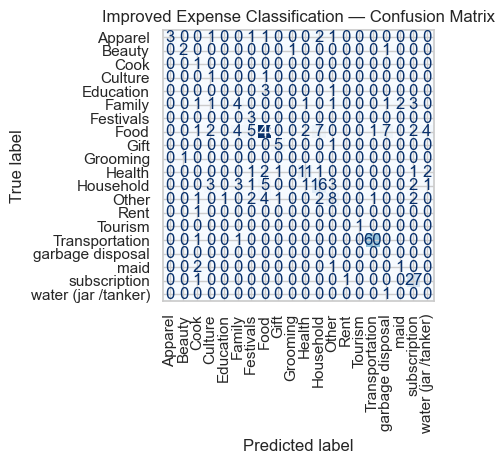


FINAL EXPERIMENT SUMMARY
Total transactions: 1996
Training transactions: 1597
Testing transactions: 399
Number of categories: 23
Best model: Linear SVM
Best accuracy: 72.43 %
Best macro F1: 0.4211

Accuracy target not achieved yet.
Further feature and model investigation is required.


In [64]:
# ============================================================
# SECTION 3.12.11 — IMPROVED EXPENSE CLASSIFICATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# 1. CREATE A SEPARATE EXPERIMENTAL DATASET
# ------------------------------------------------------------

ml_text_df = household_consumption_df[
    ["Date", "Mode", "Amount", "Note", "Category"]
].copy()

# Clean text features in this experimental copy
ml_text_df["Note"] = (
    ml_text_df["Note"]
    .fillna("No Description")
    .astype(str)
    .str.strip()
    .str.lower()
)

ml_text_df["Mode"] = (
    ml_text_df["Mode"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

# Extract date features
ml_text_df["DayOfWeek"] = ml_text_df["Date"].dt.dayofweek
ml_text_df["Month"] = ml_text_df["Date"].dt.month

# Remove original Date column
ml_text_df = ml_text_df.drop(columns=["Date"])

# Separate input features and target
X_text = ml_text_df.drop(columns=["Category"])
y_text = ml_text_df["Category"]

print("Experimental dataset shape:", ml_text_df.shape)
print("Input features shape:", X_text.shape)
print("Target shape:", y_text.shape)
print("Number of categories:", y_text.nunique())


# ------------------------------------------------------------
# 2. HANDLE CATEGORIES WITH ONLY ONE TRANSACTION
# ------------------------------------------------------------

# Identify categories with fewer than two records
category_counts_text = y_text.value_counts()
rare_categories_text = category_counts_text[
    category_counts_text < 2
].index

# Separate rare records
rare_mask_text = y_text.isin(rare_categories_text)

X_rare_text = X_text[rare_mask_text]
y_rare_text = y_text[rare_mask_text]

# Separate remaining records
X_common_text = X_text[~rare_mask_text]
y_common_text = y_text[~rare_mask_text]

# Stratified split of remaining records
X_train_text, X_test_text, y_train_text, y_test_text = (
    train_test_split(
        X_common_text,
        y_common_text,
        test_size=0.20,
        random_state=42,
        stratify=y_common_text
    )
)

# Add rare records to training data only
X_train_text = pd.concat([X_train_text, X_rare_text])
y_train_text = pd.concat([y_train_text, y_rare_text])

print("\nTraining features:", X_train_text.shape)
print("Testing features:", X_test_text.shape)
print("Training target:", y_train_text.shape)
print("Testing target:", y_test_text.shape)


# ------------------------------------------------------------
# 3. BUILD THE FEATURE PREPROCESSING PIPELINE
# ------------------------------------------------------------

# Text processing: convert Notes into numerical TF-IDF features
text_transformer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_features=10000,
    sublinear_tf=True
)

# Payment mode processing
mode_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Numerical feature processing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine all preprocessing operations
preprocessor = ColumnTransformer(
    transformers=[
        ("note", text_transformer, "Note"),
        ("mode", mode_transformer, ["Mode"]),
        (
            "numeric",
            numeric_transformer,
            ["Amount", "DayOfWeek", "Month"]
        )
    ],
    remainder="drop"
)

print("\nFeature preprocessing pipeline created successfully!")


# ------------------------------------------------------------
# 4. CREATE MULTIPLE CLASSIFICATION MODELS
# ------------------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
}


# ------------------------------------------------------------
# 5. TRAIN AND EVALUATE THE MODELS
# ------------------------------------------------------------

trained_models = {}
results = []

for model_name, classifier in models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    # Create complete pipeline
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Train using training data only
    model_pipeline.fit(X_train_text, y_train_text)

    # Predict unseen testing data
    predictions = model_pipeline.predict(X_test_text)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test_text, predictions)

    precision = precision_score(
        y_test_text,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test_text,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test_text,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test_text,
        predictions,
        average="weighted",
        zero_division=0
    )

    # Store trained model
    trained_models[model_name] = model_pipeline

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy * 100,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Macro F1:", round(macro_f1, 4))
    print("Weighted F1:", round(weighted_f1, 4))


# ------------------------------------------------------------
# 6. COMPARE ALL MODELS
# ------------------------------------------------------------

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by=["Macro F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("MODEL COMPARISON RESULTS")
print("=" * 60)

display(comparison_df)


# ------------------------------------------------------------
# 7. SELECT THE BEST MODEL
# ------------------------------------------------------------

best_model_name = comparison_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test_text)

print("\nBest model:", best_model_name)

print("\nOriginal Random Forest baseline accuracy: 46.37%")

print(
    "Improved model accuracy:",
    round(
        accuracy_score(y_test_text, best_predictions) * 100,
        2
    ),
    "%"
)


# ------------------------------------------------------------
# 8. DETAILED CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DETAILED CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test_text,
        best_predictions,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

plt.figure(figsize=(15, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test_text,
    best_predictions,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Improved Expense Classification — Confusion Matrix")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. FINAL EXPERIMENT SUMMARY
# ------------------------------------------------------------

best_accuracy = accuracy_score(
    y_test_text,
    best_predictions
) * 100

best_macro_f1 = f1_score(
    y_test_text,
    best_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 60)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 60)

print("Total transactions:", len(ml_text_df))
print("Training transactions:", len(X_train_text))
print("Testing transactions:", len(X_test_text))
print("Number of categories:", y_text.nunique())
print("Best model:", best_model_name)
print("Best accuracy:", round(best_accuracy, 2), "%")
print("Best macro F1:", round(best_macro_f1, 4))

if best_accuracy >= 80:
    print("\nAccuracy target achieved!")
else:
    print("\nAccuracy target not achieved yet.")
    print("Further feature and model investigation is required.")

### 3.12.12 — Chronological Validation Preparation

In [65]:

# ============================================================
# STEP 1 — PREPARE DATA FOR CHRONOLOGICAL VALIDATION
# ============================================================

# Create a separate copy.
# We will preserve the original dataset.

chron_df = household_consumption_df[
    ["Date", "Mode", "Amount", "Note", "Category"]
].copy()

# Ensure Date is in datetime format
chron_df["Date"] = pd.to_datetime(chron_df["Date"])

# Clean transaction descriptions
chron_df["Note"] = (
    chron_df["Note"]
    .fillna("No Description")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Clean payment mode
chron_df["Mode"] = (
    chron_df["Mode"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

# Sort transactions by date
chron_df = chron_df.sort_values(
    "Date"
).reset_index(drop=True)

# ------------------------------------------------------------
# 1. CHECK DATE COVERAGE
# ------------------------------------------------------------

print("TOTAL TRANSACTIONS:", len(chron_df))

print("FIRST TRANSACTION:", chron_df["Date"].min())

print("LAST TRANSACTION:", chron_df["Date"].max())

print("\nTRANSACTIONS PER YEAR:")

display(
    chron_df["Date"]
    .dt.year
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 2. CREATE A TEMPORARY 80:20 CHRONOLOGICAL SPLIT
# ------------------------------------------------------------

split_index = int(len(chron_df) * 0.80)

cutoff_date = chron_df.loc[
    split_index, "Date"
]

# Keep all transactions on the cutoff date in training.
# This avoids splitting transactions from the same date.

train_preview = chron_df[
    chron_df["Date"] <= cutoff_date
].copy()

test_preview = chron_df[
    chron_df["Date"] > cutoff_date
].copy()

print("\nCHRONOLOGICAL SPLIT")
print("Cutoff date:", cutoff_date)

print("Training transactions:", len(train_preview))

print("Testing transactions:", len(test_preview))

print(
    "Training percentage:",
    round(len(train_preview) / len(chron_df) * 100, 2),
    "%"
)

print(
    "Testing percentage:",
    round(len(test_preview) / len(chron_df) * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 3. CHECK CATEGORY DISTRIBUTION
# ------------------------------------------------------------

print("\nTRAINING CATEGORY DISTRIBUTION:")

display(
    train_preview["Category"]
    .value_counts()
)

print("\nTESTING CATEGORY DISTRIBUTION:")

display(
    test_preview["Category"]
    .value_counts()
)

# ------------------------------------------------------------
# 4. CHECK CATEGORIES NOT PRESENT IN TRAINING
# ------------------------------------------------------------

train_categories = set(
    train_preview["Category"].unique()
)

test_categories = set(
    test_preview["Category"].unique()
)

unseen_categories = test_categories - train_categories

print("\nCATEGORIES NOT SEEN DURING TRAINING:")

print(unseen_categories)

print(
    "\nNumber of unseen categories:",
    len(unseen_categories)
)

# ------------------------------------------------------------
# 5. VALIDATION PREPARATION SUMMARY
# ------------------------------------------------------------

print("\nCHRONOLOGICAL VALIDATION DATA INSPECTION COMPLETED!")


TOTAL TRANSACTIONS: 1996
FIRST TRANSACTION: 2015-01-01 00:00:00
LAST TRANSACTION: 2018-12-09 00:00:00

TRANSACTIONS PER YEAR:


Date
2015    317
2016    242
2017    875
2018    562
Name: count, dtype: int64


CHRONOLOGICAL SPLIT
Cutoff date: 2018-03-18 00:00:00
Training transactions: 1602
Testing transactions: 394
Training percentage: 80.26 %
Testing percentage: 19.74 %

TRAINING CATEGORY DISTRIBUTION:


Category
Food                   718
Transportation         259
Household              126
subscription           113
Other                  104
Health                  77
Family                  52
Apparel                 34
Gift                    27
Beauty                  18
maid                    15
Education               15
Festivals               13
Culture                  8
Cook                     4
Grooming                 4
Rent                     4
Tourism                  4
water (jar /tanker)      3
garbage disposal         2
Self-development         1
Social Life              1
Name: count, dtype: int64


TESTING CATEGORY DISTRIBUTION:


Category
Food                188
Household            50
Transportation       48
subscription         30
Family               19
Health               17
Apparel              13
Other                 7
Beauty                4
Festivals             3
Culture               3
Education             3
Gift                  3
Documents             2
maid                  2
Tourism               1
Self-development      1
Name: count, dtype: int64


CATEGORIES NOT SEEN DURING TRAINING:
{'Documents'}

Number of unseen categories: 1

CHRONOLOGICAL VALIDATION DATA INSPECTION COMPLETED!


In [66]:

# ============================================================
# STEP 2 — CATEGORY ELIGIBILITY AUDIT
# ============================================================

# Count categories in training and testing datasets

train_counts = train_preview["Category"].value_counts()

test_counts = test_preview["Category"].value_counts()

# Combine both distributions

category_audit = pd.DataFrame({
    "Training_Count": train_counts,
    "Testing_Count": test_counts
}).fillna(0).astype(int)

# Calculate total examples

category_audit["Total_Count"] = (
    category_audit["Training_Count"] +
    category_audit["Testing_Count"]
)

# Identify category availability

category_audit["Status"] = np.where(
    category_audit["Training_Count"] == 0,
    "Unseen in Training",
    np.where(
        category_audit["Testing_Count"] == 0,
        "No Test Examples",
        "Available in Both"
    )
)

# Identify categories with very few training examples

category_audit["Training_Risk"] = np.where(
    category_audit["Training_Count"] < 5,
    "Very Low Support",
    np.where(
        category_audit["Training_Count"] < 20,
        "Low Support",
        "Better Supported"
    )
)

# Sort by training count

category_audit = category_audit.sort_values(
    by="Training_Count",
    ascending=True
)

print("CHRONOLOGICAL CATEGORY ELIGIBILITY AUDIT")

display(category_audit)

print("\nSUMMARY")

print(
    "Total categories:",
    len(category_audit)
)

print(
    "Unseen in training:",
    (category_audit["Training_Count"] == 0).sum()
)

print(
    "Categories with fewer than 5 training examples:",
    (category_audit["Training_Count"] < 5).sum()
)

print(
    "Categories available in both datasets:",
    (
        (category_audit["Training_Count"] > 0) &
        (category_audit["Testing_Count"] > 0)
    ).sum()
)


CHRONOLOGICAL CATEGORY ELIGIBILITY AUDIT


,Training_Count,Testing_Count,Total_Count,Status,Training_Risk
Category,,,,,
Documents,0,2,2,Unseen in Training,Very Low Support
Self-development,1,1,2,Available in Both,Very Low Support
Social Life,1,0,1,No Test Examples,Very Low Support
garbage disposal,2,0,2,No Test Examples,Very Low Support
water (jar /tanker),3,0,3,No Test Examples,Very Low Support
Rent,4,0,4,No Test Examples,Very Low Support
Grooming,4,0,4,No Test Examples,Very Low Support
Cook,4,0,4,No Test Examples,Very Low Support
Tourism,4,1,5,Available in Both,Very Low Support



SUMMARY
Total categories: 23
Unseen in training: 1
Categories with fewer than 5 training examples: 9
Categories available in both datasets: 16


Training shape: (1602, 5)
Testing shape: (394, 5)

Training chronological Linear SVM...
Model training completed successfully!

Predictions generated successfully!

Total test transactions: 394
Supported test transactions: 392
Unsupported test transactions: 2

CHRONOLOGICAL LINEAR SVM RESULTS
Accuracy: 77.3 %
Macro Precision: 0.4204
Macro Recall: 0.4623
Macro F1: 0.4329
Weighted F1: 0.7856
Unsupported transactions: 2

DETAILED CLASSIFICATION REPORT
                     precision    recall  f1-score   support

            Apparel       0.77      0.77      0.77        13
             Beauty       0.67      1.00      0.80         4
               Cook       0.00      0.00      0.00         0
            Culture       0.33      0.67      0.44         3
          Education       1.00      1.00      1.00         3
             Family       0.00      0.00      0.00        19
          Festivals       0.50      0.67      0.57         3
               Food       0.91      0.90      0.91       1

<Figure size 1500x1200 with 0 Axes>

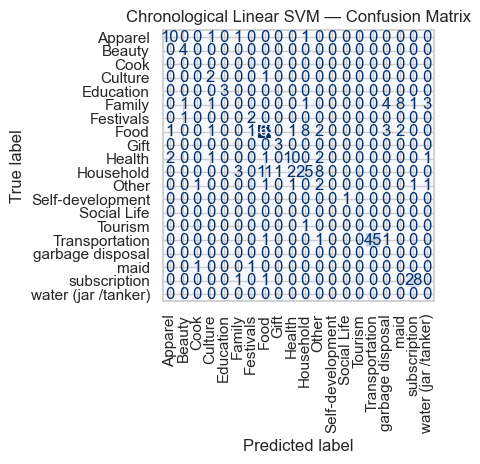

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Unsupported Transactions
0,Linear SVM - Chronological,77.295918,0.420407,0.462314,0.432893,0.785562,2



CHRONOLOGICAL VALIDATION COMPLETED!


In [67]:

# ============================================================
# STEP 3 — CHRONOLOGICAL LINEAR SVM TRAINING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. PREPARE FEATURES
# ------------------------------------------------------------

# Create a separate copy of chronological datasets

train_ml = train_preview.copy()
test_ml = test_preview.copy()

# Extract date-based features

for df in [train_ml, test_ml]:

    df["DayOfWeek"] = df["Date"].dt.dayofweek
    df["Month"] = df["Date"].dt.month

# Select input features

feature_columns = [
    "Note",
    "Amount",
    "Mode",
    "DayOfWeek",
    "Month"
]

X_train_chron = train_ml[feature_columns].copy()
X_test_chron = test_ml[feature_columns].copy()

y_train_chron = train_ml["Category"].copy()
y_test_chron = test_ml["Category"].copy()

print("Training shape:", X_train_chron.shape)
print("Testing shape:", X_test_chron.shape)


# ------------------------------------------------------------
# 2. BUILD PREPROCESSING PIPELINE
# ------------------------------------------------------------

text_transformer_chron = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_features=10000,
    sublinear_tf=True
)

mode_transformer_chron = OneHotEncoder(
    handle_unknown="ignore"
)

numeric_transformer_chron = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor_chron = ColumnTransformer(
    transformers=[
        ("note", text_transformer_chron, "Note"),
        ("mode", mode_transformer_chron, ["Mode"]),
        (
            "numeric",
            numeric_transformer_chron,
            ["Amount", "DayOfWeek", "Month"]
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 3. CREATE LINEAR SVM PIPELINE
# ------------------------------------------------------------

chron_svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor_chron),

    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    ))
])


# ------------------------------------------------------------
# 4. TRAIN MODEL
# ------------------------------------------------------------

print("\nTraining chronological Linear SVM...")

chron_svm_model.fit(
    X_train_chron,
    y_train_chron
)

print("Model training completed successfully!")


# ------------------------------------------------------------
# 5. GENERATE PREDICTIONS
# ------------------------------------------------------------

chron_predictions = chron_svm_model.predict(
    X_test_chron
)

print("\nPredictions generated successfully!")

# Identify categories the model has never learned

known_categories = set(chron_svm_model.classes_)

supported_mask = y_test_chron.isin(known_categories)

unsupported_count = (~supported_mask).sum()

print("\nTotal test transactions:", len(y_test_chron))

print("Supported test transactions:", supported_mask.sum())

print("Unsupported test transactions:", unsupported_count)


# ------------------------------------------------------------
# 6. EVALUATE SUPPORTED TEST TRANSACTIONS
# ------------------------------------------------------------

y_test_supported = y_test_chron[supported_mask]

predictions_supported = chron_predictions[supported_mask]

chron_accuracy = accuracy_score(
    y_test_supported,
    predictions_supported
)

chron_precision = precision_score(
    y_test_supported,
    predictions_supported,
    average="macro",
    zero_division=0
)

chron_recall = recall_score(
    y_test_supported,
    predictions_supported,
    average="macro",
    zero_division=0
)

chron_macro_f1 = f1_score(
    y_test_supported,
    predictions_supported,
    average="macro",
    zero_division=0
)

chron_weighted_f1 = f1_score(
    y_test_supported,
    predictions_supported,
    average="weighted",
    zero_division=0
)


# ------------------------------------------------------------
# 7. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CHRONOLOGICAL LINEAR SVM RESULTS")
print("=" * 60)

print("Accuracy:", round(chron_accuracy * 100, 2), "%")

print("Macro Precision:", round(chron_precision, 4))

print("Macro Recall:", round(chron_recall, 4))

print("Macro F1:", round(chron_macro_f1, 4))

print("Weighted F1:", round(chron_weighted_f1, 4))

print("Unsupported transactions:", unsupported_count)


# ------------------------------------------------------------
# 8. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nDETAILED CLASSIFICATION REPORT")

print(
    classification_report(
        y_test_supported,
        predictions_supported,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

plt.figure(figsize=(15, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test_supported,
    predictions_supported,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Chronological Linear SVM — Confusion Matrix")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. SAVE RESULTS FOR COMPARISON
# ------------------------------------------------------------

chron_results = pd.DataFrame([{
    "Model": "Linear SVM - Chronological",
    "Accuracy": chron_accuracy * 100,
    "Macro Precision": chron_precision,
    "Macro Recall": chron_recall,
    "Macro F1": chron_macro_f1,
    "Weighted F1": chron_weighted_f1,
    "Unsupported Transactions": unsupported_count
}])

display(chron_results)

print("\nCHRONOLOGICAL VALIDATION COMPLETED!")


In [68]:

# ============================================================
# STEP 4 — CHRONOLOGICAL PREDICTION ERROR ANALYSIS
# ============================================================

# 1. Create prediction audit

prediction_audit = test_ml[
    ["Date", "Note", "Amount", "Mode"]
].copy()

prediction_audit["Actual_Category"] = (
    y_test_chron.to_numpy()
)

prediction_audit["Predicted_Category"] = (
    chron_predictions
)

prediction_audit["Correct"] = (
    prediction_audit["Actual_Category"]
    == prediction_audit["Predicted_Category"]
)

prediction_audit["Supported_Category"] = (
    prediction_audit["Actual_Category"]
    .isin(known_categories)
)


# 2. Overall prediction summary

print("OVERALL PREDICTION SUMMARY")

print("Total transactions:", len(prediction_audit))

print(
    "Correct predictions:",
    (
        prediction_audit["Correct"] &
        prediction_audit["Supported_Category"]
    ).sum()
)

print(
    "Incorrect predictions:",
    (
        (~prediction_audit["Correct"]) &
        prediction_audit["Supported_Category"]
    ).sum()
)

print(
    "Unsupported transactions:",
    (~prediction_audit["Supported_Category"]).sum()
)


# 3. Category-wise performance

supported_audit = prediction_audit[
    prediction_audit["Supported_Category"]
].copy()

category_performance = (
    supported_audit
    .groupby("Actual_Category")
    .agg(
        Total_Transactions=("Correct", "count"),
        Correct_Predictions=("Correct", "sum"),
        Accuracy=("Correct", "mean")
    )
    .sort_values("Accuracy")
)

category_performance["Accuracy"] *= 100

print("\nCATEGORY-WISE ACCURACY")

display(category_performance.round(2))


# 4. Incorrectly classified transactions

incorrect_predictions = supported_audit[
    ~supported_audit["Correct"]
].copy()

print("\nINCORRECT PREDICTIONS")

print("Total errors:", len(incorrect_predictions))

display(
    incorrect_predictions[
        [
            "Date",
            "Note",
            "Amount",
            "Actual_Category",
            "Predicted_Category"
        ]
    ].head(25)
)


# 5. Most common classification mistakes

mistake_summary = (
    incorrect_predictions
    .groupby(
        ["Actual_Category", "Predicted_Category"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("\nMOST COMMON CLASSIFICATION MISTAKES")

display(mistake_summary.head(15))


# 6. Unsupported category transactions

unsupported_predictions = prediction_audit[
    ~prediction_audit["Supported_Category"]
].copy()

print("\nUNSUPPORTED CATEGORY TRANSACTIONS")

display(unsupported_predictions)


print("\nPREDICTION ERROR ANALYSIS COMPLETED!")


OVERALL PREDICTION SUMMARY
Total transactions: 394
Correct predictions: 303
Incorrect predictions: 89
Unsupported transactions: 2

CATEGORY-WISE ACCURACY


,Total_Transactions,Correct_Predictions,Accuracy
Actual_Category,,,
Family,19,0,0.00
maid,2,0,0.00
Tourism,1,0,0.00
Self-development,1,0,0.00
Other,7,2,28.57
Household,50,25,50.00
Health,17,10,58.82
Culture,3,2,66.67
Festivals,3,2,66.67



INCORRECT PREDICTIONS
Total errors: 89


,Date,Note,Amount,Actual_Category,Predicted_Category
1603,2018-03-20,no note,17.0,Other,Cook
1608,2018-03-21,no note,50.0,Family,garbage disposal
1618,2018-03-23,finding next job,100.0,Culture,Food
1620,2018-03-25,french crossiant,80.0,Food,Culture
1638,2018-04-01,cockroach injection,270.0,Household,Food
1644,2018-04-03,no note,450.0,Family,maid
1650,2018-04-07,no note,350.0,Family,maid
1652,2018-04-13,family thyroid test + cbc,700.0,Health,Apparel
1657,2018-04-15,"vessels for sugar, coffee and tea",799.0,Household,Gift
1658,2018-04-15,body mist,525.0,Family,Culture



MOST COMMON CLASSIFICATION MISTAKES


,Actual_Category,Predicted_Category,Count
26,Household,Food,11
8,Family,maid,8
16,Food,Household,8
29,Household,Other,8
7,Family,garbage disposal,4
25,Household,Family,3
10,Family,water (jar /tanker),3
18,Food,garbage disposal,3
20,Health,Apparel,2
19,Food,maid,2



UNSUPPORTED CATEGORY TRANSACTIONS


,Date,Note,Amount,Mode,Actual_Category,Predicted_Category,Correct,Supported_Category
1640,2018-04-01,aadhar address change,50.0,Saving Bank account 1,Documents,Family,False,False
1763,2018-06-03,aadhar puc card delivery,50.0,Credit Card,Documents,Other,False,False



PREDICTION ERROR ANALYSIS COMPLETED!


In [69]:

# ============================================================
# STEP 5 — DETAILED CLASSIFICATION DIAGNOSIS
# ============================================================

# 1. Create Description_Status BEFORE creating family_errors

prediction_audit["Description_Status"] = np.where(
    prediction_audit["Note"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["no note", "no description", "nan", ""]),
    "No Useful Description",
    "Description Available"
)


# ------------------------------------------------------------
# 2. INVESTIGATE ALL FAMILY TRANSACTIONS
# ------------------------------------------------------------

family_errors = prediction_audit[
    prediction_audit["Actual_Category"] == "Family"
].copy()

print("FAMILY TRANSACTION ANALYSIS")

print("Total Family transactions:", len(family_errors))

print(
    "Correct predictions:",
    family_errors["Correct"].sum()
)

print("\nWhat did the model predict for Family?")

display(
    family_errors["Predicted_Category"].value_counts()
)

print("\nAll Family transactions:")

display(
    family_errors[
        [
            "Date",
            "Note",
            "Amount",
            "Mode",
            "Predicted_Category"
        ]
    ]
)


# ------------------------------------------------------------
# 3. INVESTIGATE RARE CATEGORY PREDICTIONS
# ------------------------------------------------------------

print("\nRARE CATEGORY PREDICTION ANALYSIS")

prediction_counts = (
    prediction_audit["Predicted_Category"]
    .value_counts()
)

rare_prediction_audit = pd.DataFrame({
    "Training_Count": train_counts,
    "Test_Prediction_Count": prediction_counts
}).fillna(0).astype(int)

rare_prediction_audit = rare_prediction_audit.sort_values(
    "Training_Count"
)

display(rare_prediction_audit)


# ------------------------------------------------------------
# 4. CHECK TRANSACTION DESCRIPTION QUALITY
# ------------------------------------------------------------

print("\nTRANSACTION DESCRIPTION QUALITY")

display(
    prediction_audit
    .groupby("Description_Status")
    .size()
    .to_frame("Transaction_Count")
)


# ------------------------------------------------------------
# 5. COMPARE FAMILY DESCRIPTION QUALITY
# ------------------------------------------------------------

print("\nFAMILY DESCRIPTION QUALITY")

display(
    family_errors["Description_Status"].value_counts()
)


print("\nDIAGNOSIS COMPLETED SUCCESSFULLY!")


FAMILY TRANSACTION ANALYSIS
Total Family transactions: 19
Correct predictions: 0

What did the model predict for Family?


Predicted_Category
maid                   8
garbage disposal       4
water (jar /tanker)    3
Culture                1
Household              1
Beauty                 1
subscription           1
Name: count, dtype: int64


All Family transactions:


,Date,Note,Amount,Mode,Predicted_Category
1608,2018-03-21,no note,50.0,Cash,garbage disposal
1644,2018-04-03,no note,450.0,Cash,maid
1650,2018-04-07,no note,350.0,Cash,maid
1658,2018-04-15,body mist,525.0,Credit Card,Culture
1683,2018-04-26,no note,1000.0,Cash,maid
1687,2018-04-28,no note,500.0,Cash,maid
1699,2018-05-02,no note,500.0,Cash,maid
1709,2018-05-05,no note,600.0,Cash,maid
1714,2018-05-08,no note,100.0,Cash,garbage disposal
1719,2018-05-08,bows,398.0,Credit Card,Household



RARE CATEGORY PREDICTION ANALYSIS


,Training_Count,Test_Prediction_Count
Social Life,1,1
Self-development,1,0
garbage disposal,2,8
water (jar /tanker),3,5
Rent,4,0
Tourism,4,0
Cook,4,2
Grooming,4,0
Culture,8,6
Festivals,13,4



TRANSACTION DESCRIPTION QUALITY


,Transaction_Count
Description_Status,
Description Available,362
No Useful Description,32



FAMILY DESCRIPTION QUALITY


Description_Status
No Useful Description    16
Description Available     3
Name: count, dtype: int64


DIAGNOSIS COMPLETED SUCCESSFULLY!


In [70]:

# FIX — FAMILY DESCRIPTION QUALITY

# Re-create family_errors after Description_Status was added

family_errors = prediction_audit[
    prediction_audit["Actual_Category"] == "Family"
].copy()

print("FAMILY DESCRIPTION QUALITY")

display(
    family_errors["Description_Status"].value_counts()
)

print("\nDIAGNOSIS COMPLETED SUCCESSFULLY!")


FAMILY DESCRIPTION QUALITY


Description_Status
No Useful Description    16
Description Available     3
Name: count, dtype: int64


DIAGNOSIS COMPLETED SUCCESSFULLY!


In [71]:

# ============================================================
# STEP 6 — TRAINING DATA QUALITY INVESTIGATION
# ============================================================

# 1. Inspect Family training transactions

family_train_audit = train_preview[
    train_preview["Category"] == "Family"
].copy()

family_train_audit["Clean_Note"] = (
    family_train_audit["Note"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

unhelpful_notes = [
    "", "no note", "no description", "nan"
]

family_train_audit["Useful_Description"] = (
    ~family_train_audit["Clean_Note"].isin(unhelpful_notes)
)

print("FAMILY TRAINING DATA")

print("Total Family training transactions:",
      len(family_train_audit))

print("Useful descriptions:",
      family_train_audit["Useful_Description"].sum())

print("Unhelpful descriptions:",
      (~family_train_audit["Useful_Description"]).sum())

print("\nFamily transaction descriptions:")

display(
    family_train_audit[
        ["Date", "Note", "Amount", "Mode"]
    ].head(30)
)


# 2. Analyse description quality across categories

train_quality = train_preview.copy()

train_quality["Clean_Note"] = (
    train_quality["Note"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

train_quality["Useful_Description"] = (
    ~train_quality["Clean_Note"].isin(unhelpful_notes)
)

quality_summary = (
    train_quality
    .groupby("Category")
    .agg(
        Total_Transactions=("Note", "count"),
        Useful_Descriptions=("Useful_Description", "sum")
    )
)

quality_summary["Unhelpful_Descriptions"] = (
    quality_summary["Total_Transactions"]
    - quality_summary["Useful_Descriptions"]
)

quality_summary["Useful_Description_Percent"] = (
    quality_summary["Useful_Descriptions"]
    / quality_summary["Total_Transactions"] * 100
)

print("\nDESCRIPTION QUALITY BY CATEGORY")

display(
    quality_summary.sort_values(
        "Useful_Description_Percent"
    ).round(2)
)


# 3. Inspect Family category note patterns

print("\nMOST COMMON FAMILY DESCRIPTIONS")

display(
    family_train_audit["Clean_Note"]
    .value_counts()
    .head(20)
)


# 4. Compare Family transaction amounts

print("\nFAMILY AMOUNT SUMMARY")

display(
    family_train_audit["Amount"].describe()
)

print("\nTRAINING DATA QUALITY INVESTIGATION COMPLETED!")


FAMILY TRAINING DATA
Total Family training transactions: 52
Useful descriptions: 20
Unhelpful descriptions: 32

Family transaction descriptions:


,Date,Note,Amount,Mode
320,2016-01-07,family mobile service provider recharge,2599.0,Saving Bank account 1
364,2016-04-08,ipad cover,260.0,Saving Bank account 1
387,2016-05-12,tonic,155.0,Cash
400,2016-06-19,family exam form,905.0,Saving Bank account 1
409,2016-07-08,pet psychology,750.0,Saving Bank account 1
432,2016-08-23,no note,2000.0,Saving Bank account 1
443,2016-09-10,scratch guard ipad,249.0,Saving Bank account 1
448,2016-09-14,baggit purse,437.0,Saving Bank account 1
457,2016-10-13,scratch guard ipad,249.0,Saving Bank account 1
469,2016-10-27,undated planner - june shop,1119.2,Saving Bank account 1



DESCRIPTION QUALITY BY CATEGORY


,Total_Transactions,Useful_Descriptions,Unhelpful_Descriptions,Useful_Description_Percent
Category,,,,
Cook,4,0,4,0.00
Rent,4,0,4,0.00
garbage disposal,2,0,2,0.00
maid,15,1,14,6.67
Family,52,20,32,38.46
subscription,113,68,45,60.18
water (jar /tanker),3,2,1,66.67
Food,718,648,70,90.25
Household,126,115,11,91.27



MOST COMMON FAMILY DESCRIPTIONS


Clean_Note
no note                                    32
scratch guard ipad                          2
change                                      2
tonic                                       1
ipad cover                                  1
family mobile service provider recharge     1
pet psychology                              1
baggit purse                                1
undated planner - june shop                 1
himalaya shampoo                            1
family exam form                            1
leggings                                    1
sweater                                     1
syrup                                       1
h&m clothes                                 1
fab india                                   1
for utensils                                1
trouser                                     1
belt + bow                                  1
Name: count, dtype: int64


FAMILY AMOUNT SUMMARY


count      52.000000
mean     1355.619231
std      1523.660914
min        20.000000
25%       229.250000
50%       625.000000
75%      2000.000000
max      5000.000000
Name: Amount, dtype: float64


TRAINING DATA QUALITY INVESTIGATION COMPLETED!


In [72]:

# ============================================================
# STEP 6 — CATEGORY OVERLAP INVESTIGATION
# ============================================================

# 1. Select the main category pairs that the model confused

category_pairs = [
    ("Household", "Food"),
    ("Food", "Household"),
    ("Family", "maid"),
    ("Household", "Other"),
    ("Family", "garbage disposal")
]

# 2. Display the actual test transactions behind these mistakes

print("=" * 65)
print("TEST TRANSACTIONS: CATEGORY CONFUSION")
print("=" * 65)

for actual, predicted in category_pairs:

    pair_errors = incorrect_predictions[
        (incorrect_predictions["Actual_Category"] == actual) &
        (incorrect_predictions["Predicted_Category"] == predicted)
    ]

    print(f"\nACTUAL: {actual} | PREDICTED: {predicted}")
    print("Number of mistakes:", len(pair_errors))

    display(
        pair_errors[
            ["Date", "Note", "Amount", "Actual_Category",
             "Predicted_Category"]
        ]
    )


# 3. Compare training examples from the confused categories

print("\n" + "=" * 65)
print("TRAINING DATA: CATEGORY DESCRIPTION COMPARISON")
print("=" * 65)

categories_to_inspect = [
    "Household",
    "Food",
    "Family",
    "maid",
    "Other",
    "garbage disposal"
]

for category in categories_to_inspect:

    category_examples = train_ml[
        train_ml["Category"] == category
    ][["Note", "Amount", "Mode", "Category"]]

    print(f"\nCATEGORY: {category}")
    print("Training examples:", len(category_examples))

    display(category_examples.head(15))


# 4. Check description quality in the training data

print("\n" + "=" * 65)
print("TRAINING DESCRIPTION QUALITY BY CATEGORY")
print("=" * 65)

training_description_audit = train_ml.copy()

training_description_audit["Description_Status"] = np.where(
    training_description_audit["Note"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["no note", "no description", "nan", ""]),
    "No Useful Description",
    "Description Available"
)

description_summary = (
    training_description_audit
    .groupby(["Category", "Description_Status"])
    .size()
    .unstack(fill_value=0)
)

display(description_summary)


print("\nCATEGORY OVERLAP INVESTIGATION COMPLETED!")


TEST TRANSACTIONS: CATEGORY CONFUSION

ACTUAL: Household | PREDICTED: Food
Number of mistakes: 11


,Date,Note,Amount,Actual_Category,Predicted_Category
1638,2018-04-01,cockroach injection,270.0,Household,Food
1665,2018-04-16,cockroach injection,270.0,Household,Food
1749,2018-05-27,soap + dahya pav kg,75.0,Household,Food
1754,2018-06-01,5 litres can distilled water,100.0,Household,Food
1800,2018-06-27,mouse pad,100.0,Household,Food
1806,2018-06-29,3 bulbs 3 pencil cells,270.0,Household,Food
1807,2018-06-29,tulsi plant+ pot,70.0,Household,Food
1816,2018-07-04,pav kg chana dal,24.0,Household,Food
1867,2018-08-01,harpik 1l,165.0,Household,Food
1889,2018-08-13,5 litres can distilled water,100.0,Household,Food



ACTUAL: Food | PREDICTED: Household
Number of mistakes: 8


,Date,Note,Amount,Actual_Category,Predicted_Category
1685,2018-04-26,noodles packet,30.0,Food,Household
1692,2018-04-30,toast packet,45.0,Food,Household
1697,2018-05-02,1 packet,69.0,Food,Household
1843,2018-07-21,toast packet,45.0,Food,Household
1849,2018-07-26,toast packet,40.0,Food,Household
1937,2018-09-05,toast packet,45.0,Food,Household
1940,2018-09-07,toast packet,20.0,Food,Household
1973,2018-11-05,1 packet,20.0,Food,Household



ACTUAL: Family | PREDICTED: maid
Number of mistakes: 8


,Date,Note,Amount,Actual_Category,Predicted_Category
1644,2018-04-03,no note,450.0,Family,maid
1650,2018-04-07,no note,350.0,Family,maid
1683,2018-04-26,no note,1000.0,Family,maid
1687,2018-04-28,no note,500.0,Family,maid
1699,2018-05-02,no note,500.0,Family,maid
1709,2018-05-05,no note,600.0,Family,maid
1854,2018-07-28,no note,200.0,Family,maid
1929,2018-08-31,no note,1000.0,Family,maid


... (15 outputs left out)

,Note,Amount,Mode,Category
125,no note,17.0,Cash,garbage disposal
163,no note,50.0,Cash,garbage disposal



TRAINING DESCRIPTION QUALITY BY CATEGORY


Description_Status,Description Available,No Useful Description
Category,,
Apparel,34,0
Beauty,17,1
Cook,0,4
Culture,8,0
Education,15,0
Family,20,32
Festivals,13,0
Food,648,70
Gift,27,0



CATEGORY OVERLAP INVESTIGATION COMPLETED!



### 3.12.14 — Category Overlap Investigation: Findings

The category overlap investigation revealed several data-quality
and classification challenges.

**1. Household and Food**
- The model confused Household and Food in both directions.
- Household also contains diverse purchases such as repairs,
  electronics and household supplies.
- These categories need clearer classification boundaries.

**2. Family**
- 20 out of 52 training transactions had useful descriptions.
- 32 out of 52 had no useful descriptions.
- Family represents the beneficiary of an expense rather than
  the type of purchase.
- This creates overlap with categories such as Apparel and Health.

**3. Rare categories**
- maid: 15 training examples, only 1 useful description.
- garbage disposal: 2 training examples, no useful descriptions.
- Cook: 4 training examples, no useful descriptions.
- Rent: 4 training examples, no useful descriptions.

**Conclusion**

The investigation indicates that classification performance is
limited partly by data quality, category ambiguity and insufficient
training examples.

The current Linear SVM model remains our best candidate based on
the experiments completed so far. However, it requires further
validation and should not yet be considered production-ready.

Future improvements should include category standardisation,
better transaction descriptions, clearer category definitions
and a fallback for uncertain predictions.


### 3.12.12 Final Exploratory Data Analysis and Machine Learning Findings

#### 1. Dataset Overview
- Original cleaned dataset: 2,452 transactions.
- Refined household consumption dataset: 1,996 transactions.
- Historical coverage: January 2015 to December 2018 (48 months).
- Number of household expense categories: 23.

#### 2. Data Quality
- Missing values in the cleaned dataset: 0.
- Duplicate records: 0.
- Date and DateTime columns were converted into appropriate datetime formats.
- Subcategory values were standardised.
- Financial transfers, investments and savings-related transactions were investigated and separated from household consumption.

#### 3. Financial Insights
- Transportation and Household were among the largest consumption categories by amount.
- Food represented the highest transaction frequency.
- Cash was frequently used for smaller purchases.
- Credit card transactions had a higher average transaction amount than cash transactions.
- Statistical outlier analysis identified 18 transactions above the 99th-percentile threshold of ₹5,000.

#### 4. Machine Learning Experiments

An initial expense classification experiment was performed using Amount, Mode, DayOfWeek and Month.

A second experiment incorporated transaction descriptions using TF-IDF, along with payment mode and numerical features.

| Model | Accuracy |
|---|---:|
| Baseline Random Forest | 46.37% |
| Logistic Regression with TF-IDF | 64.66% |
| Linear SVM with TF-IDF | 72.43% |

Linear SVM achieved the highest accuracy in the current experiments, demonstrating an improvement over the baseline Random Forest model.

#### 5. Dataset and Model Limitations
- The dataset contains imbalanced expense categories.
- Several categories have very few transactions, limiting reliable model learning.
- The historical dataset represents one household's spending patterns and may not generalise to all users.
- The classification experiments used a random train-test split; chronological validation is still required.
- The dataset does not contain monthly budget limits, savings goals or actual budget exhaustion outcomes.
- Further model optimisation and validation are required before production integration.

#### 6. Conclusion

The exploratory data analysis provided valuable insights into household spending behaviour, financial transactions, payment preferences and monthly consumption patterns.

The machine learning experiments demonstrated that incorporating transaction descriptions through TF-IDF improved expense classification performance compared with the initial baseline model.

This EDA establishes a foundation for developing ForeSight's financial management and intelligence systems. The findings can support future development of spending forecasting, unusual spending detection, budget management, savings recommendations and personalised financial insights.

Further machine learning development and validation will be performed in dedicated notebooks before integrating trained models into the ForeSight application.